## 一、指标选定
 
1. 算力： H100 equivalents （等效 H100）

 拓展备选： CURRENT H100 （原生H100数量）
- 含义：仅统计已经部署的原生H100芯片，其他型号GPU不参与计算；
- 定位：不作为主指标；时间充裕可做拓展对比；缺陷是无法代表数据中心全部总算力。
- 🔍可深入点：对比「折算等效算力」和「原生H100算力」的分析结果，观察两套指标下功率关联是否一致，如果结果差异大，可以讨论芯片型号结构对功耗的影响。
 
2. 功率： Power (MW) （总功率，兆瓦）
-含义是数据中心整体耗电，包含IT服务器、冷却系统、配电配套全部设施，贴合研究“数据中心整体电力需求”的方向；
-原始数据仅1条缺失，数据质量好；

 备选  IT power (MW) ，仅统计IT硬件本身耗电，作为补充，不作为主线。
 
拓展派生概念：\text{PUE}= \text{Power(MW)} \div \text{IT power(MW)}
- 作用：衡量冷却、配电基础设施带来的额外电力损耗；
- 注意：PUE本身不包含算力信息，不能单独当作能源效率指标，仅适合放在讨论部分。
- 可深入点：后续可以观察PUE高低会不会影响能源效率；看高PUE的数据中心，同等算力下是否消耗更多总功率。
 
3. 派生指标：能源效率
公式：
\text{能源效率} = \text{H100 equivalents} \div \text{Power (MW)}
 为什么做这个指标
1. 直接回答核心问题：每兆瓦电力，可以支撑多少等效 H100；
2. 数值越大：同等耗电下承载算力越高，能源效率越高；
3. 数学约束：分子分母都不能等于0，除法才有意义，所以清洗阶段必须过滤0值。
 
4. 补充拓展指标（可选，不替换主指标）
 
eff_it = H100 equivalents / IT power(MW) ：基于IT硬件功率的算力效率；
 
- 可深入点：对比 eff_total 与 eff_it ，拆分硬件本身效率和机房冷却配套带来的效率损失。
- 说明：以上拓展指标时间紧张可以直接跳过，不影响主线核心分析。

In [2]:
import pandas as pd
import matplotlib.pyplot as plt

plt.rcParams['font.sans-serif'] = ['SimHei']
plt.rcParams['axes.unicode_minus'] = False

# 读取 csv（row_audit 和其他文件放同一个文件夹）
df_main = pd.read_csv("data_centers.csv")
df_chip = pd.read_csv("data_center_chip_quantities.csv")
df_time = pd.read_csv("data_center_timelines.csv")
df_audit = pd.read_csv("row_audit.csv")

print("==== data_centers（主候选表） ====")
print("行数,列数：", df_main.shape)
print("列名：")
for col in df_main.columns:
    print(col)

print("\n==== data_center_chip_quantities（芯片数量表） ====")
print("行数,列数：", df_chip.shape)
print("列名：")
for col in df_chip.columns:
    print(col)

print("\n==== data_center_timelines（时间线表） ====")
print("行数,列数：", df_time.shape)
print("列名：")
for col in df_time.columns:
    print(col)

# ========== 冻结日切分 ==========
df_merge = pd.concat([df_time, df_audit[["is_projection"]]], axis=1)
df_actual = df_merge[df_merge["is_projection"] == False].copy()

print("\n==== 冻结日切分处理结果 ====")
print(f"原始时间线总行数：{len(df_merge)}")
print(f"剔除 projection 行数：{df_merge['is_projection'].sum()}")
print(f"保留真实观测行数：{len(df_actual)}")

==== data_centers（主候选表） ====
行数,列数： (95, 16)
列名：
Name
Current H100 equivalents
Current power (MW)
Current total capital cost (2025 USD billions)
Owner
Users
Selected Sources
Calculations sheet
Project
Current chip types
All chip types
Investors
Construction companies
Energy companies
Country
Address

==== data_center_chip_quantities（芯片数量表） ====
行数,列数： (239, 11)
列名：
Handle
Date
Chip type
Number of Units
Chip type source
Number of Units source
Owner
User
Notes
Data center
Timeline

==== data_center_timelines（时间线表） ====
行数,列数： (567, 14)
列名：
Data center
Date
Construction status
Buildings operational
IT power (MW)
Power (MW)
H100 equivalents
Performance (8-bit OP/s)
Total capital cost (2025 USD billions)
Compute cost (2025 USD billions)
Construction cost (2025 USD billions)
Annual operating cost (2025 USD billions)
Water use (MGD)
Current H100 equivalents (from Data center)

==== 冻结日切分处理结果 ====
原始时间线总行数：567
剔除 projection 行数：98
保留真实观测行数：469


## 二、探查：查看缺失、分布
### 输入：原始数据集 df_time ，选取3个核心研究字段，无任何筛选
​作用：探索性数据分析，摸底原始数据质量，提前识别缺失、大量0值、极端离群样本
1. 查看缺失数量，评估数据质量，决定清洗策略；
2. 通过均值、四分位数、最大最小值了解数值分布；
3. 属于探索性数据分析，先摸底数据，不盲目直接计算、画图。

In [3]:
# 1. 探查：查看缺失、分布
core_cols = ["H100 equivalents", "Power (MW)", "IT power (MW)"]
print("====【原始全部样本（含projection）】缺失统计====")
print(df_time[core_cols].isna().sum())
print("\n====【原始全部样本（含projection）】描述统计====")
print(df_time[core_cols].describe())

print("\n" + "="*60)
print("====【冻结日后过滤：仅真实观测 df_actual】缺失统计====")
print(df_actual[core_cols].isna().sum())
print("\n====【冻结日后过滤：仅真实观测 df_actual】描述统计====")
print(df_actual[core_cols].describe())


====【原始全部样本（含projection）】缺失统计====
H100 equivalents    3
Power (MW)          1
IT power (MW)       1
dtype: int64

====【原始全部样本（含projection）】描述统计====
       H100 equivalents   Power (MW)  IT power (MW)
count      5.640000e+02   566.000000     566.000000
mean       2.365283e+05   209.788691     161.808985
std        5.971702e+05   355.490409     271.211295
min        0.000000e+00     0.000000       0.000000
25%        0.000000e+00     0.000000       0.000000
50%        5.509651e+04    92.000000      72.000000
75%        2.093091e+05   264.500000     211.000000
max        5.103588e+06  2715.000000    2263.000000

====【冻结日后过滤：仅真实观测 df_actual】缺失统计====
H100 equivalents    3
Power (MW)          1
IT power (MW)       1
dtype: int64

====【冻结日后过滤：仅真实观测 df_actual】描述统计====
       H100 equivalents   Power (MW)  IT power (MW)
count      4.660000e+02   468.000000     468.000000
mean       2.412014e+05   215.032391     166.067192
std        5.772214e+05   355.330733     272.728517
min        0.000000e+

### 输出：各列缺失样本数量；count、mean、std、min、25%、50%、75%、max描述统计量表
 
 缺失统计
- H100 equivalents ：3条空值
- Power (MW) ：1条空值
- IT power (MW) ：1条空值
解读：整体缺失很少。但是要注意：拓展数据集df_full要求三列同时非空，所以会同时丢掉3个字段任意为空的行，相比主线数据集会损失一部分样本。

 describe描述统计
​ count：该字段非空样本数量   
- 等效算力564条；总功率、IT功率各566条。
​ mean均值  
- 平均等效H100：236528；平均总功率209.79MW；平均IT功率161.81MW。
​ std标准差：全部数值很大。
解读：各个数据中心规模差距极其悬殊，样本分布高度离散，存在极端大的数据中心。
​ min最小值：全部为0
​ 25%四分位数：全部为0
解读：四分之一以上记录算力、功率等于0；代表规划阶段、尚未投运的数据中心。这部分样本不能做除法计算效率，清洗阶段必须过滤 >0 。
​ 50%中位数
- 一半数据中心等效H100小于55096.5；总功率小于92MW；IT功率小于72MW。
​ 75%四分位数
- 75%的数据中心不会超过该规模。
​ max最大值
- 存在超级大规模数据中心，是潜在离群点，后续散点图会体现。
 
### 可深入思考点:

统计数值=0的样本占比；查看极端最大值对应样本信息，判断是否为特殊数据中心

1. 零值样本问题
原始数据存在大量数值为0的记录，代表规划中、尚未投产的数据中心。
- 可统计零值样本占全部样本的百分比，说明数据集构成；
- 零值样本无法开展能源效率计算，后续分析必须过滤。
2. 数据分布特征
标准差明显大于均值，呈现右偏分布。
- 少数超大规模数据中心拉高均值；
- 样本之间算力、功率规模差距悬殊。
3. 不同筛选条件带来样本量差异
后续会生成两套清洗数据集，筛选规则不一样，样本数量不同：
- 宽松筛选：只需要等效算力、总功率有效大于0，样本多，作为主线分析使用；
- 严格筛选：额外要求IT硬件功率同时有效大于0，样本变少，存在样本选择偏差，仅用作拓展分析，不做主结论。
4. 极端离群样本的稳健性问题
数据存在极大值样本。
- 当前阶段全部保留，不剔除；
- 需要说明极端样本可能对相关系数、整体趋势产生干扰；
- 进阶可以对比保留/剔除离群点的结果，也可查看极端样本对应的数据中心类型。
5. 缺失值情况
整体缺失数量很低，但拓展分析需要三个变量同时无缺失，会间接造成样本损耗。
 
### 简短小结：原始数据缺失较少，但要关注未投产零记录、右偏分布、离群点、不同筛选下的样本损耗，讨论分析结果的稳健程度。

## 三、 数据清洗与派生指标构建
1. 缺失值过滤：删除「等效 H100 算力、总功率、IT 硬件功率」任意为空的观测。
2. 数值筛选：保证三个核心变量都大于 0，规避除零错误，剔除不合理样本。
3. 派生指标计算
   - `eff_total`：总功率口径能源效率 = 等效算力 ÷ 数据中心总功耗
   - `eff_it`：IT 硬件口径能源效率 = 等效算力 ÷ IT 设备功耗
   - `pue`：电源使用效率 = 总功耗 ÷ IT 设备功耗
4. 样本统计与预览：输出样本量，预览前几行，校验清洗结果。

In [4]:
# ==========旧：基于全部样本（含projection，保留用于对比，后续分析不再用这组）==========
# 清洗、生成派生指标（严格筛选的拓展子集）
# 删除三个字段任意为空的行
df_full = df_time.dropna(subset=["H100 equivalents", "Power (MW)", "IT power (MW)"])

# 过滤：算力、总功率、IT功率必须>0；避免除法报错
df_full = df_full[(df_full["H100 equivalents"] > 0)
                  & (df_full["Power (MW)"] > 0)
                  & (df_full["IT power (MW)"] > 0)]

# 派生指标
df_full["eff_total"] = df_full["H100 equivalents"] / df_full["Power (MW)"]    #总功率口径能源效率
df_full["eff_it"] = df_full["H100 equivalents"] / df_full["IT power (MW)"]   #IT硬件口径能源效率
df_full["pue"] = df_full["Power (MW)"] / df_full["IT power (MW)"]            #PUE电源使用效率

# ==========新：仅真实观测 df_actual（正式后续分析使用！）==========
df_actual_full = df_actual.dropna(subset=["H100 equivalents", "Power (MW)", "IT power (MW)"])

df_actual_full = df_actual_full[(df_actual_full["H100 equivalents"] > 0)
                                & (df_actual_full["Power (MW)"] > 0)
                                & (df_actual_full["IT power (MW)"] > 0)]

df_actual_full["eff_total"] = df_actual_full["H100 equivalents"] / df_actual_full["Power (MW)"]
df_actual_full["eff_it"] = df_actual_full["H100 equivalents"] / df_actual_full["IT power (MW)"]
df_actual_full["pue"] = df_actual_full["Power (MW)"] / df_actual_full["IT power (MW)"]


# 输出样本规模对比
print(f"原始总记录数：{len(df_time)}")
print(f"【含projection】拓展分析可用记录数 df_full：{len(df_full)}")
print(f"【仅真实观测】拓展分析可用记录数 df_actual_full：{len(df_actual_full)}")

#预览数据（看干净观测集）
preview_cols = ["H100 equivalents", "Power (MW)", "IT power (MW)",
                "eff_total", "eff_it", "pue"]
print("\n=====仅真实观测样本预览 df_actual_full =====")
print(df_actual_full[preview_cols].head())


原始总记录数：567
【含projection】拓展分析可用记录数 df_full：358
【仅真实观测】拓展分析可用记录数 df_actual_full：300

=====仅真实观测样本预览 df_actual_full =====
   H100 equivalents  Power (MW)  IT power (MW)   eff_total       eff_it  \
2      2.779181e+05       323.0          239.0  860.427679  1162.837408   
3      2.779181e+05       323.0          239.0  860.427679  1162.837408   
4      5.558363e+05       661.0          490.0  840.902089  1134.359757   
5      1.111673e+06      1276.0          946.0  871.216741  1175.129558   
6      1.824154e+06      2065.0         1531.0  883.367367  1191.478519   

        pue  
2  1.351464  
3  1.351464  
4  1.348980  
5  1.348837  
6  1.348792  


经过缺失过滤+数值>0筛选后，正式分析样本：含预测358条；冻结日过滤后仅真实观测300条。后续能效、相关性分析全部采用300条 df_actual_full 。

In [5]:
# 导出带派生指标的 timeline 清洗结果
df_full.to_csv("timeline_cleaned.csv", index=False, encoding="utf-8-sig")

# 导出带派生指标的 timeline 清洗结果
# 供后续分析（相关性 / 能效传导）使用的仅真实观测数据
df_actual_full.to_csv("timeline_cleaned_actual.csv", index=False, encoding="utf-8-sig")

print("已导出：timeline_cleaned_actual.csv")
print(f"行数：{len(df_actual_full)}，仅含冻结日前真实观测样本")

已导出：timeline_cleaned_actual.csv
行数：300，仅含冻结日前真实观测样本


✅ 正式分析数据集：timeline_cleaned_actual.csv，n = 300

In [6]:
# 精简清洗数据
df_out = df_full[["Data center", "H100 equivalents", "Power (MW)", "IT power (MW)", "eff_total", "eff_it", "pue"]]
df_out.to_csv("timeline_slim.csv", index=False, encoding="utf-8-sig")

# 精简清洗数据（仅真实观测）
df_out = df_actual_full[["Data center", "H100 equivalents", "Power (MW)", "IT power (MW)", "eff_total", "eff_it", "pue"]]
df_out.to_csv("timeline_slim_actual.csv", index=False, encoding="utf-8-sig")

print(f"精简表导出成功，文件名：timeline_slim_actual.csv，行数：{len(df_out)}")

精简表导出成功，文件名：timeline_slim_actual.csv，行数：300


In [8]:
# =====【旧：原始全部样本（含 projection，留作对比）】主线数据集：宽松筛选，不用 IT power =====
df_clean = df_time.dropna(subset=["H100 equivalents", "Power (MW)"])
df_clean = df_clean[(df_clean["H100 equivalents"] > 0) & (df_clean["Power (MW)"] > 0)]
df_clean["eff_total"] = df_clean["H100 equivalents"] / df_clean["Power (MW)"]

print(f"【含 projection】主线样本数量：{len(df_clean)}")
print("\n====【含 projection】主线数据描述统计====")
print(df_clean[["H100 equivalents", "Power (MW)", "eff_total"]].describe())

# =====【新：仅真实观测，正式用！】主线数据集：宽松筛选，不用 IT power =====
df_clean_actual = df_actual.dropna(subset=["H100 equivalents", "Power (MW)"])
df_clean_actual = df_clean_actual[(df_clean_actual["H100 equivalents"] > 0) & (df_clean_actual["Power (MW)"] > 0)]
df_clean_actual["eff_total"] = df_clean_actual["H100 equivalents"] / df_clean_actual["Power (MW)"]

print("\n" + "="*60)
print(f"【仅真实观测】主线样本数量 df_clean_actual：{len(df_clean_actual)}")
print("\n====【仅真实观测】主线数据描述统计====")
print(df_clean_actual[["H100 equivalents", "Power (MW)", "eff_total"]].describe())

【含 projection】主线样本数量：358

====【含 projection】主线数据描述统计====
       H100 equivalents   Power (MW)    eff_total
count      3.580000e+02   358.000000   358.000000
mean       3.726312e+05   330.668713   871.464334
std        7.152135e+05   399.708216   489.686554
min        5.821122e+03     6.640000   138.294194
25%        6.114199e+04    99.500000   553.576703
50%        1.513542e+05   202.000000   801.860724
75%        3.001355e+05   391.250000   912.049042
max        5.103588e+06  2715.000000  3183.611066

【仅真实观测】主线样本数量 df_clean_actual：300

====【仅真实观测】主线数据描述统计====
       H100 equivalents   Power (MW)    eff_total
count      3.000000e+02   300.000000   300.000000
mean       3.746661e+05   334.247197   874.677671
std        6.840989e+05   396.289346   492.212232
min        5.821122e+03     6.640000   138.294194
25%        5.856493e+04    98.750000   566.169452
50%        1.551289e+05   208.500000   797.758841
75%        3.239010e+05   401.250000   912.049042
max        4.562911e+06  2715.000

## 四、分析：等效算力与总功率
筛选条件：等效 H100 总算力、总功率非空且大于 0
样本量：358
指标：
- H100 equivalents：等效总算力
- Power (MW)：总功率
- eff_total：总口径能源效率

目标：绘制散点图，计算皮尔逊相关系数，观察二者线性关联。

### 代码说明
1. `import matplotlib.pyplot as plt`
导入绘图库，绘制散点图。

2. `plt.figure(figsize=(8,5))`
新建画布，设置图片长宽。

3. `plt.scatter(..., alpha=0.6)`
绘制散点。
- `alpha`：透明度，取值区间 `[0, 1]`
  - 越靠近 0：越透明；越靠近 1：越不透明。
  - 选择 0.6：既可以分辨重叠点的聚集情况，又不会因为颜色过深，全部糊成一块黑团。

4. `xlabel / ylabel / title`
设置横轴、纵轴、图标题。图标题为：等效 H100 总算力与数据中心总功率关系。

5. `plt.grid(alpha=0.3)`
绘制网格；网格透明度设为 0.3，颜色浅，辅助读图，不遮挡散点。

6. `plt.show()`
渲染展示图像。

7. `.corr(method="pearson")`
计算皮尔逊相关系数，评估线性关联强弱。
⚠️ 皮尔逊对离群点敏感；相关不等于因果。

8. `:.3f`
输出保留三位小数，方便记录结果。

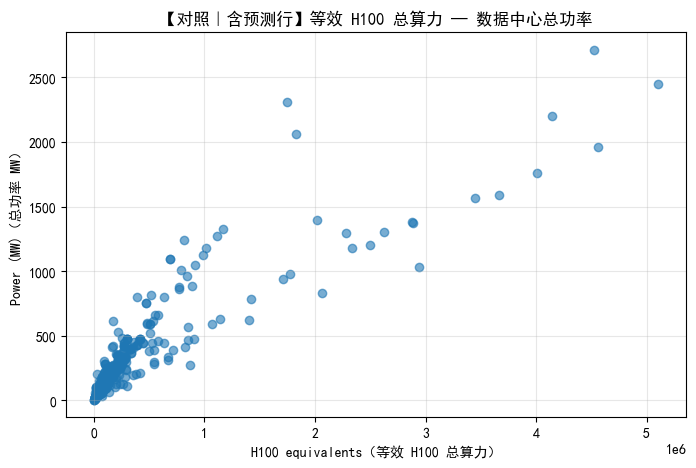

【含 projection】皮尔逊相关系数：0.895


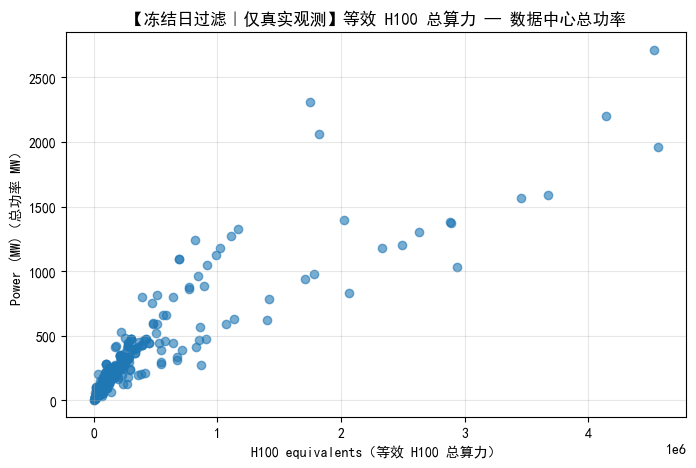

【仅真实观测】皮尔逊相关系数：0.885


In [10]:
import matplotlib.pyplot as plt

# ========== 旧图：含 projection ==========
plt.figure(figsize=(8,5))
plt.scatter(df_clean["H100 equivalents"], df_clean["Power (MW)"], alpha=0.6)
plt.xlabel("H100 equivalents（等效 H100 总算力）")
plt.ylabel("Power (MW)（总功率 MW）")
plt.title("【对照｜含预测行】等效 H100 总算力 — 数据中心总功率")
plt.grid(alpha=0.3)
plt.savefig("scatter_with_proj.png", dpi=300, bbox_inches="tight")
plt.show()

r_pearson_old = df_clean["H100 equivalents"].corr(df_clean["Power (MW)"], method="pearson")
print(f"【含 projection】皮尔逊相关系数：{r_pearson_old:.3f}")


# ========== 新图：仅真实观测 ==========
plt.figure(figsize=(8,5))
plt.scatter(df_clean_actual["H100 equivalents"], df_clean_actual["Power (MW)"], alpha=0.6)
plt.xlabel("H100 equivalents（等效 H100 总算力）")
plt.ylabel("Power (MW)（总功率 MW）")
plt.title("【冻结日过滤｜仅真实观测】等效 H100 总算力 — 数据中心总功率")
plt.grid(alpha=0.3)
plt.savefig("scatter_actual_only.png", dpi=300, bbox_inches="tight")
plt.show()

r_pearson_new = df_clean_actual["H100 equivalents"].corr(df_clean_actual["Power (MW)"], method="pearson")
print(f"【仅真实观测】皮尔逊相关系数：{r_pearson_new:.3f}")


### 散点图与相关性结果
【含 projection】等效 H100 总算力与数据中心总功率的皮尔逊相关系数为0.895；
【仅真实观测】等效 H100 总算力与数据中心总功率的皮尔逊相关系数为 0.885。

- 观测：散点整体呈上升趋势，二者存在较强的正线性关联；大量中小规模数据中心集中在图左下角，同时存在少量规模很大的离群样本。
- 局限：皮尔逊相关对极端离群点敏感；较高的相关系数仅说明二者在观测上联动，不代表存在因果关系。

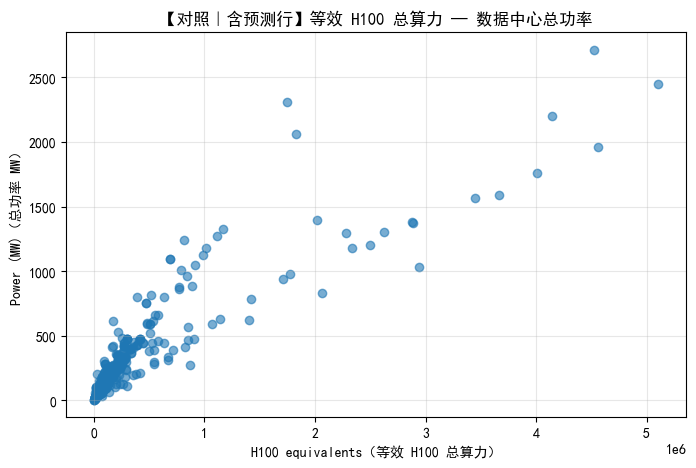

【含 projection】皮尔逊相关系数：0.895


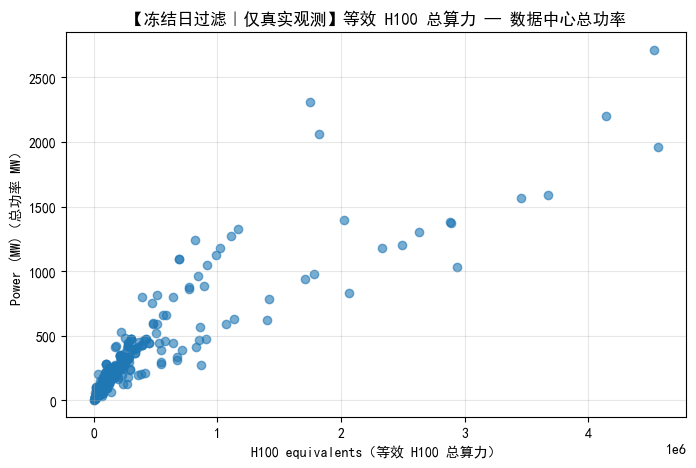

【仅真实观测】皮尔逊相关系数：0.885


In [11]:
import matplotlib.pyplot as plt

# ========== 对照：含 projection ==========
plt.figure(figsize=(8,5))
plt.scatter(df_clean["H100 equivalents"], df_clean["Power (MW)"], alpha=0.6)
plt.xlabel("H100 equivalents（等效 H100 总算力）")
plt.ylabel("Power (MW)（总功率 MW）")
plt.title("【对照｜含预测行】等效 H100 总算力 — 数据中心总功率")
plt.grid(alpha=0.3)
plt.savefig("scatter_power_with_proj.png", dpi=300, bbox_inches="tight")
plt.show()

r_pearson_old = df_clean["H100 equivalents"].corr(df_clean["Power (MW)"], method="pearson")
print(f"【含 projection】皮尔逊相关系数：{r_pearson_old:.3f}")


# ========== 正式：冻结日过滤，仅真实观测 ==========
plt.figure(figsize=(8,5))
plt.scatter(df_clean_actual["H100 equivalents"], df_clean_actual["Power (MW)"], alpha=0.6)
plt.xlabel("H100 equivalents（等效 H100 总算力）")
plt.ylabel("Power (MW)（总功率 MW）")
plt.title("【冻结日过滤｜仅真实观测】等效 H100 总算力 — 数据中心总功率")
plt.grid(alpha=0.3)
plt.savefig("scatter_power_actual.png", dpi=300, bbox_inches="tight")
plt.show()

r_pearson_new = df_clean_actual["H100 equivalents"].corr(df_clean_actual["Power (MW)"], method="pearson")
print(f"【仅真实观测】皮尔逊相关系数：{r_pearson_new:.3f}")


## 五、分析等效 H100 总算力与 IT 硬件功率
利用同一份有效样本，探究等效算力与 IT 硬件功率之间的关联。
目标：绘制散点图，计算皮尔逊相关系数，观察二者线性关系。
绘图参数说明：
- `figsize=(8,5)`：科研常用横向画布，便于观察趋势
- `alpha=0.6`：散点透明度，识别重叠聚集
- `grid(alpha=0.3)`：辅助网格，主次分明
- `dpi=300`：保存高清图片，先保存再展示

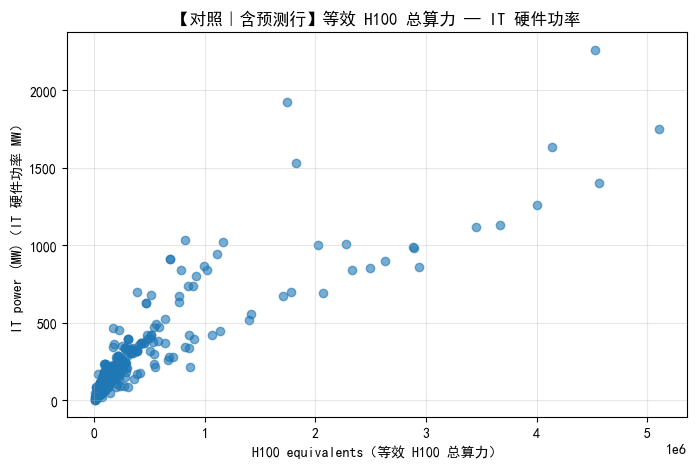

【含 projection】等效算力与 IT 硬件功率皮尔逊相关系数：0.874


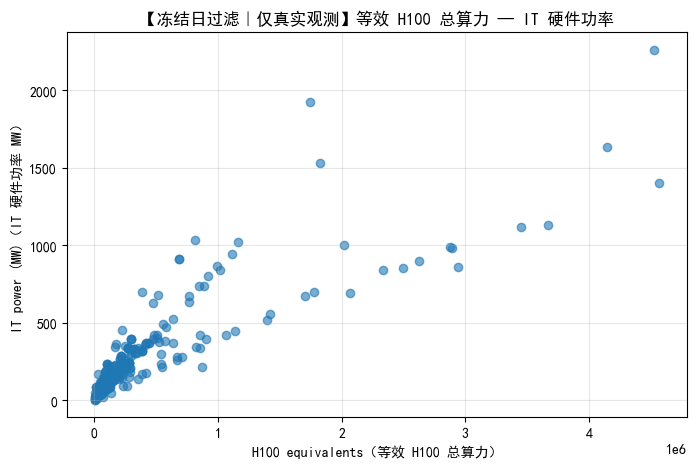

【仅真实观测】等效算力与 IT 硬件功率皮尔逊相关系数：0.865


In [12]:
import matplotlib.pyplot as plt

# ==========【对照｜含 projection】==========
plt.figure(figsize=(8, 5))
plt.scatter(df_full["H100 equivalents"], df_full["IT power (MW)"], alpha=0.6)
plt.xlabel("H100 equivalents（等效 H100 总算力）")
plt.ylabel("IT power (MW)（IT 硬件功率 MW）")
plt.title("【对照｜含预测行】等效 H100 总算力 — IT 硬件功率")
plt.grid(alpha=0.3)
plt.savefig("scatter_itpower_with_proj.png", dpi=300, bbox_inches="tight")
plt.show()

r_pearson_it_old = df_full["H100 equivalents"].corr(df_full["IT power (MW)"], method="pearson")
print(f"【含 projection】等效算力与 IT 硬件功率皮尔逊相关系数：{r_pearson_it_old:.3f}")


# ==========【正式｜仅真实观测】==========
plt.figure(figsize=(8, 5))
plt.scatter(df_actual_full["H100 equivalents"], df_actual_full["IT power (MW)"], alpha=0.6)
plt.xlabel("H100 equivalents（等效 H100 总算力）")
plt.ylabel("IT power (MW)（IT 硬件功率 MW）")
plt.title("【冻结日过滤｜仅真实观测】等效 H100 总算力 — IT 硬件功率")
plt.grid(alpha=0.3)
plt.savefig("scatter_itpower_actual.png", dpi=300, bbox_inches="tight")
plt.show()

r_pearson_it_new = df_actual_full["H100 equivalents"].corr(df_actual_full["IT power (MW)"], method="pearson")
print(f"【仅真实观测】等效算力与 IT 硬件功率皮尔逊相关系数：{r_pearson_it_new:.3f}")

### 结果分析：等效 H100 总算力与 IT 硬件功率
皮尔逊相关系数：0.865
- 观测：散点整体呈上升趋势，二者存在较强正线性关联；中小规模样本集中在左下角，同时存在少量大规模离群样本。
- 局限：皮尔逊相关对极端离群点敏感；高相关仅代表观测上联动，不能判定因果。

## 六、拓展分析：PUE 与总口径能源效率
目标：绘制散点图，计算皮尔逊相关系数，观察二者线性关联。
绘图参数：
- `figsize=(8,5)`：横向布局，便于观察趋势
- `alpha=0.6`：散点透明度，识别点的聚集
- `grid(alpha=0.3)`：浅色网格辅助读图
- `dpi=300`，先保存再展示，防止空白图

### PUE（电源使用效率）
公式：
$$\text{PUE}=\frac{\text{数据中心总功耗}}{\text{IT 设备功耗}}$$  (数据中心总能耗/IT设备功耗）

- 含义：衡量配套设施（制冷、配电等）带来的额外能耗。
- 解读：PUE 越接近 1，配套能耗占比越低，机房能耗表现越好；必然大于 1。
- 在本研究中：探究 PUE 与总口径能源效率之间的关联。

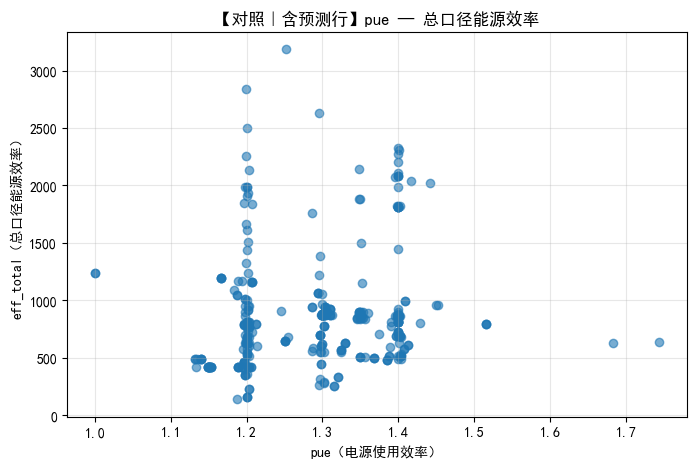

【含 projection】pue 与总口径能源效率皮尔逊相关系数：0.159


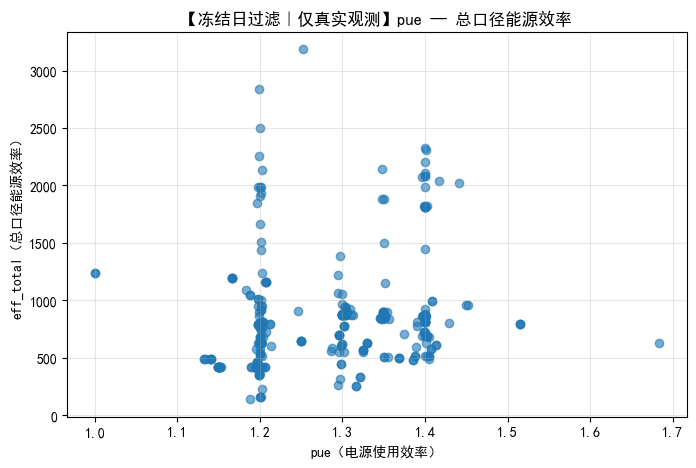

【仅真实观测】pue 与总口径能源效率皮尔逊相关系数：0.169


In [13]:
import matplotlib.pyplot as plt

# ==========【对照｜含 projection】保留不动 ==========
plt.figure(figsize=(8, 5))
plt.scatter(df_full["pue"], df_full["eff_total"], alpha=0.6)
plt.xlabel("pue（电源使用效率）")
plt.ylabel("eff_total（总口径能源效率）")
plt.title("【对照｜含预测行】pue — 总口径能源效率")
plt.grid(alpha=0.3)
plt.savefig("scatter_pue_eff_with_proj.png", dpi=300, bbox_inches="tight")
plt.show()

r_pearson_pue_old = df_full["pue"].corr(df_full["eff_total"], method="pearson")
print(f"【含 projection】pue 与总口径能源效率皮尔逊相关系数：{r_pearson_pue_old:.3f}")


# ==========【正式｜仅真实观测｜要放进汇报】新增 ==========
plt.figure(figsize=(8, 5))
plt.scatter(df_actual_full["pue"], df_actual_full["eff_total"], alpha=0.6)
plt.xlabel("pue（电源使用效率）")
plt.ylabel("eff_total（总口径能源效率）")
plt.title("【冻结日过滤｜仅真实观测】pue — 总口径能源效率")
plt.grid(alpha=0.3)
plt.savefig("scatter_pue_eff_actual.png", dpi=300, bbox_inches="tight")
plt.show()

r_pearson_pue_new = df_actual_full["pue"].corr(df_actual_full["eff_total"], method="pearson")
print(f"【仅真实观测】pue 与总口径能源效率皮尔逊相关系数：{r_pearson_pue_new:.3f}")

### 拓展结果分析：电源使用效率与总口径能源效率
皮尔逊相关系数：0.169

- 观测：散点分布散乱，没有明显线性趋势，二者仅存在极弱正线性关联；
- 注意：右侧存在少量离群样本，有可能对相关系数产生扰动；
- 结论：在本数据集下，没有证据表明 PUE 和总口径能源效率有较强的线性关系。

## 七、稳健性检验：等效 H100 总算力与总功率、IT 硬件功率
子集名称：`df_robust_power`、`df_robust_it`
思路：
1. 针对「算力—总功率」「算力—IT 功率」两组，原始散图存在右上角极端离群样本，可能扰动皮尔逊相关系数；
2. 原始数据集 `df_full` 保持不变，新建两个筛选子集：
   - `df_robust_power`：用于算力与总功率稳健分析
   - `df_robust_it`：用于算力与 IT 硬件功率稳健分析
3. 根据散点视觉设置阈值，剔除极端样本；
4. 重新绘图、重算皮尔逊相关，对比剔除前后系数，判断结论是否稳定；
5. 筛选阈值记录在报告中，保证可复现。

 ① 算力 ↔ 总功率

【对照｜含 projection】剔除前样本量：358
【对照｜含 projection】剔除后（df_robust_power）样本量：352


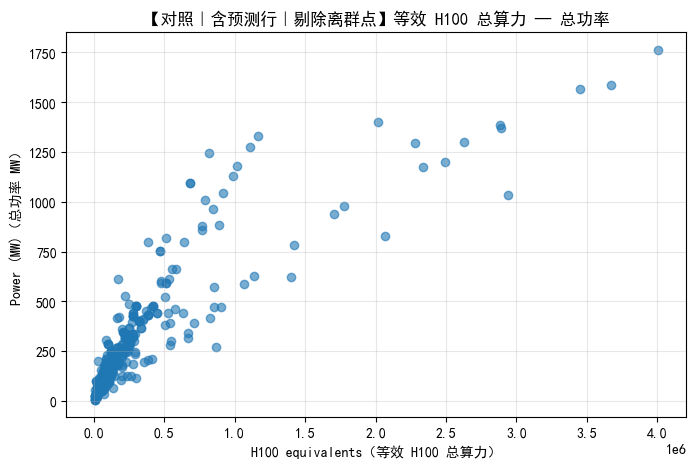

【对照｜含 projection】剔除离群点后算力与总功率皮尔逊相关系数：0.868

【正式｜仅真实观测】剔除前样本量：300
【正式｜仅真实观测】剔除后（df_robust_power_actual）样本量：295


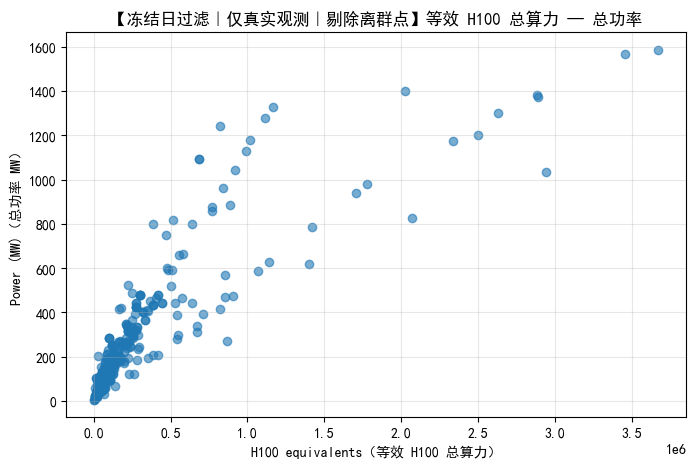

【正式｜仅真实观测】剔除离群点后算力与总功率皮尔逊相关系数：0.862


In [14]:
# ==========【对照｜基于 df_full（含 projection）】不动 ==========
# 新建稳健子集 df_robust_power，原始 df_full 不动
df_robust_power = df_full[
    (df_full["H100 equivalents"] > 0)
    & (df_full["H100 equivalents"] < 4.5e6)
    & (df_full["Power (MW)"] < 1800)
]

# 输出样本量对比
print(f"【对照｜含 projection】剔除前样本量：{len(df_full)}")
print(f"【对照｜含 projection】剔除后（df_robust_power）样本量：{len(df_robust_power)}")

import matplotlib.pyplot as plt
plt.figure(figsize=(8, 5))
plt.scatter(df_robust_power["H100 equivalents"], df_robust_power["Power (MW)"], alpha=0.6)

plt.xlabel("H100 equivalents（等效 H100 总算力）")
plt.ylabel("Power (MW)（总功率 MW）")
plt.title("【对照｜含预测行｜剔除离群点】等效 H100 总算力 — 总功率")
plt.grid(alpha=0.3)

plt.savefig("scatter_power_robust_with_proj.png", dpi=300, bbox_inches="tight")
plt.show()

r_robust_power_old = df_robust_power["H100 equivalents"].corr(df_robust_power["Power (MW)"], method="pearson")
print(f"【对照｜含 projection】剔除离群点后算力与总功率皮尔逊相关系数：{r_robust_power_old:.3f}")


# ==========【正式｜基于 df_actual_full｜冻结日真实观测】新增 ==========
df_robust_power_actual = df_actual_full[
    (df_actual_full["H100 equivalents"] > 0)
    & (df_actual_full["H100 equivalents"] < 4.5e6)
    & (df_actual_full["Power (MW)"] < 1800)
]

print("\n" + "="*60)
print(f"【正式｜仅真实观测】剔除前样本量：{len(df_actual_full)}")
print(f"【正式｜仅真实观测】剔除后（df_robust_power_actual）样本量：{len(df_robust_power_actual)}")

plt.figure(figsize=(8, 5))
plt.scatter(df_robust_power_actual["H100 equivalents"], df_robust_power_actual["Power (MW)"], alpha=0.6)

plt.xlabel("H100 equivalents（等效 H100 总算力）")
plt.ylabel("Power (MW)（总功率 MW）")
plt.title("【冻结日过滤｜仅真实观测｜剔除离群点】等效 H100 总算力 — 总功率")
plt.grid(alpha=0.3)

plt.savefig("scatter_power_robust_actual.png", dpi=300, bbox_inches="tight")
plt.show()

r_robust_power_new = df_robust_power_actual["H100 equivalents"].corr(df_robust_power_actual["Power (MW)"], method="pearson")
print(f"【正式｜仅真实观测】剔除离群点后算力与总功率皮尔逊相关系数：{r_robust_power_new:.3f}")

### 稳健性检验结果（df_robust_power_actual）
- 剔除前样本量：300
- 剔除后样本量：295
- 剔除离群点后皮尔逊相关系数：0.862

解读：剔除少量极端样本后，等效 H100 总算力与总功率依旧保持较强正相关，结论稳健，二者正向依赖关系不是由少数离群样本主导。


### 进一步稳健性检验｜收紧筛选阈值
子集名称：`df_robust_power_new`
- 问题：上一轮筛选阈值偏宽松，部分视觉离群样本仍保留在子集内；
- 调整方案：下调算力、总功率的筛选上限；
- 目的：对比多组不同阈值下相关系数变化，而不是只靠一张图“删掉不好看的点”；
- 报告要点：所有筛选阈值都要记录，不能凭观感随意删样本。

【对照｜含 projection】剔除前：358
【对照｜含 projection】新稳健子集 df_robust_power_new：348


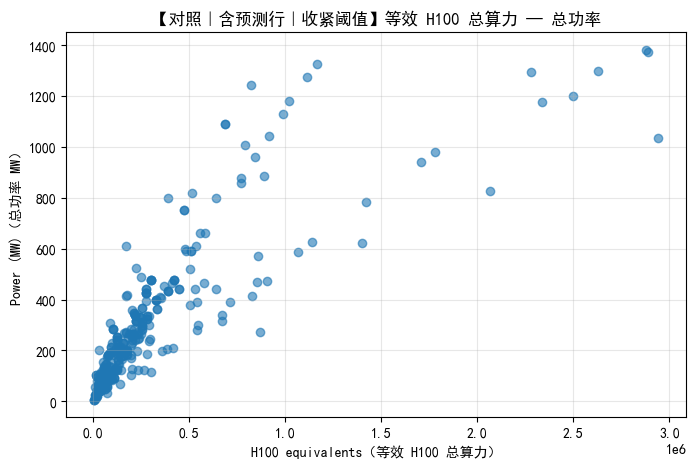

【对照｜含 projection】收紧阈值后算力与总功率皮尔逊相关系数：0.843

【正式｜仅真实观测】剔除前：300
【正式｜仅真实观测】收紧阈值稳健子集：292


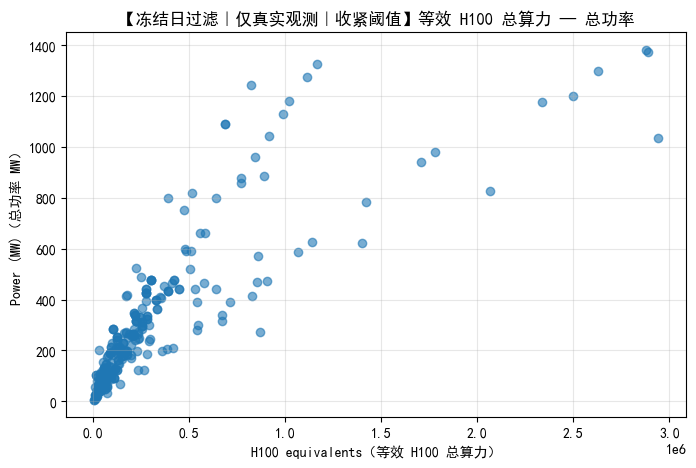

【正式｜仅真实观测】收紧阈值后算力与总功率皮尔逊相关系数：0.841


In [15]:
# ==========【对照｜基于 df_full（含 projection）】保留原逻辑 ==========
# 重新构造稳健子集，收紧门槛
df_robust_power_new = df_full[
    (df_full["H100 equivalents"] > 0)
    & (df_full["H100 equivalents"] < 3.2e6)   # 把算力上限往下压
    & (df_full["Power (MW)"] < 1400)          # 总功率上限也收紧
]

print(f"【对照｜含 projection】剔除前：{len(df_full)}")
print(f"【对照｜含 projection】新稳健子集 df_robust_power_new：{len(df_robust_power_new)}")

import matplotlib.pyplot as plt
plt.figure(figsize=(8, 5))
plt.scatter(df_robust_power_new["H100 equivalents"], df_robust_power_new["Power (MW)"], alpha=0.6)

plt.xlabel("H100 equivalents（等效 H100 总算力）")
plt.ylabel("Power (MW)（总功率 MW）")
plt.title("【对照｜含预测行｜收紧阈值】等效 H100 总算力 — 总功率")
plt.grid(alpha=0.3)

plt.savefig("scatter_power_robust_tight_with_proj.png", dpi=300, bbox_inches="tight")
plt.show()

r_robust_tight_old = df_robust_power_new["H100 equivalents"].corr(df_robust_power_new["Power (MW)"], method="pearson")
print(f"【对照｜含 projection】收紧阈值后算力与总功率皮尔逊相关系数：{r_robust_tight_old:.3f}")


# ==========【正式｜基于 df_actual_full｜冻结日真实观测】新增 ==========
df_robust_power_tight_actual = df_actual_full[
    (df_actual_full["H100 equivalents"] > 0)
    & (df_actual_full["H100 equivalents"] < 3.2e6)
    & (df_actual_full["Power (MW)"] < 1400)
]

print("\n" + "="*60)
print(f"【正式｜仅真实观测】剔除前：{len(df_actual_full)}")
print(f"【正式｜仅真实观测】收紧阈值稳健子集：{len(df_robust_power_tight_actual)}")

plt.figure(figsize=(8, 5))
plt.scatter(df_robust_power_tight_actual["H100 equivalents"], df_robust_power_tight_actual["Power (MW)"], alpha=0.6)

plt.xlabel("H100 equivalents（等效 H100 总算力）")
plt.ylabel("Power (MW)（总功率 MW）")
plt.title("【冻结日过滤｜仅真实观测｜收紧阈值】等效 H100 总算力 — 总功率")
plt.grid(alpha=0.3)

plt.savefig("scatter_power_robust_tight_actual.png", dpi=300, bbox_inches="tight")
plt.show()

r_robust_tight_new = df_robust_power_tight_actual["H100 equivalents"].corr(df_robust_power_tight_actual["Power (MW)"], method="pearson")
print(f"【正式｜仅真实观测】收紧阈值后算力与总功率皮尔逊相关系数：{r_robust_tight_new:.3f}")

### 稳健性检验（收紧阈值）结果分析（df_robust_power_tight_actual）
子集名称：`df_robust_power_tight_actual`
- 剔除前样本量：300
- 收紧阈值后样本量：292
- 皮尔逊相关系数：0.841

解读：进一步收紧算力、总功率上限，少量样本被剔除；相关系数小幅下降，但依旧维持较高水平。说明等效 H100 总算力与总功率的强正相关结论稳健，并不单纯依靠少数极端样本。

 ② 算力 ↔ IT功率

【对照｜含 projection｜算力—IT 功率】剔除前样本量：358
【对照｜含 projection｜算力—IT 功率】新稳健子集 df_robust_it_new 样本量：349


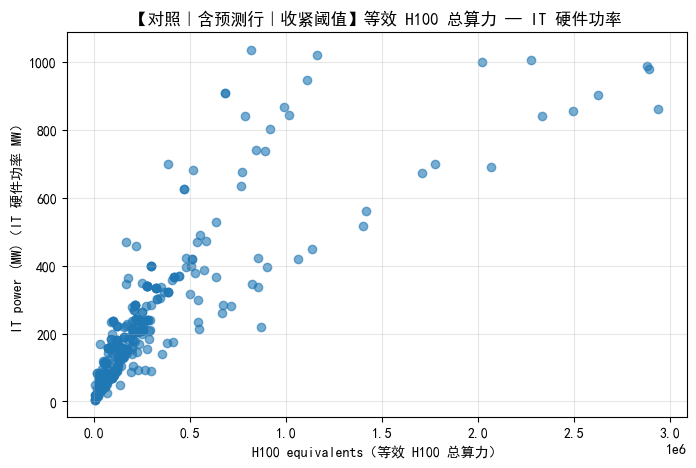

【对照｜含 projection】收紧阈值后算力与 IT 硬件功率皮尔逊相关系数：0.829

【正式｜仅真实观测｜算力—IT 功率】剔除前样本量：300
【正式｜仅真实观测｜算力—IT 功率】收紧阈值稳健子集 df_robust_it_tight_actual 样本量：293


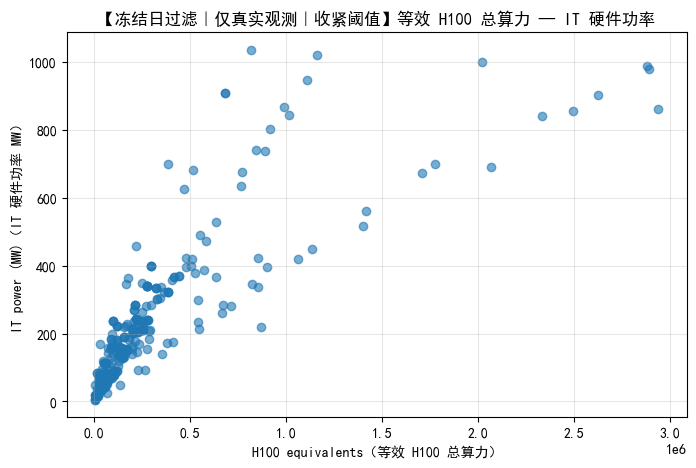

【正式｜仅真实观测】收紧阈值后算力与 IT 硬件功率皮尔逊相关系数：0.828


In [16]:
# ==========【对照｜基于 df_full（含 projection）】保留原逻辑 ==========
# 构造稳健子集 df_robust_it_new，和上面一套阈值保持一致，方便对比
df_robust_it_new = df_full[
    (df_full["H100 equivalents"] > 0)        # 算力大于 0
    & (df_full["H100 equivalents"] < 3.2e6)  # 算力上限
    & (df_full["IT power (MW)"] < 1400)      # IT 硬件功率上限
]

# 打印样本数量，方便前后对比
print(f"【对照｜含 projection｜算力—IT 功率】剔除前样本量：{len(df_full)}")
print(f"【对照｜含 projection｜算力—IT 功率】新稳健子集 df_robust_it_new 样本量：{len(df_robust_it_new)}")

import matplotlib.pyplot as plt
# 创建画布
plt.figure(figsize=(8, 5))
# 绘制散点图
plt.scatter(df_robust_it_new["H100 equivalents"], df_robust_it_new["IT power (MW)"], alpha=0.6)

# 坐标轴、标题
plt.xlabel("H100 equivalents（等效 H100 总算力）")
plt.ylabel("IT power (MW)（IT 硬件功率 MW）")
plt.title("【对照｜含预测行｜收紧阈值】等效 H100 总算力 — IT 硬件功率")
plt.grid(alpha=0.3)

# 保存图片在前，防止空白图
plt.savefig("scatter_it_robust_tight_with_proj.png", dpi=300, bbox_inches="tight")
plt.show()

# 计算皮尔逊相关系数
r_robust_it_old = df_robust_it_new["H100 equivalents"].corr(df_robust_it_new["IT power (MW)"], method="pearson")
print(f"【对照｜含 projection】收紧阈值后算力与 IT 硬件功率皮尔逊相关系数：{r_robust_it_old:.3f}")


# ==========【正式｜基于 df_actual_full｜冻结日真实观测】新增 ==========
df_robust_it_tight_actual = df_actual_full[
    (df_actual_full["H100 equivalents"] > 0)
    & (df_actual_full["H100 equivalents"] < 3.2e6)
    & (df_actual_full["IT power (MW)"] < 1400)
]

print("\n" + "="*60)
print(f"【正式｜仅真实观测｜算力—IT 功率】剔除前样本量：{len(df_actual_full)}")
print(f"【正式｜仅真实观测｜算力—IT 功率】收紧阈值稳健子集 df_robust_it_tight_actual 样本量：{len(df_robust_it_tight_actual)}")

plt.figure(figsize=(8, 5))
plt.scatter(df_robust_it_tight_actual["H100 equivalents"], df_robust_it_tight_actual["IT power (MW)"], alpha=0.6)

plt.xlabel("H100 equivalents（等效 H100 总算力）")
plt.ylabel("IT power (MW)（IT 硬件功率 MW）")
plt.title("【冻结日过滤｜仅真实观测｜收紧阈值】等效 H100 总算力 — IT 硬件功率")
plt.grid(alpha=0.3)

plt.savefig("scatter_it_robust_tight_actual.png", dpi=300, bbox_inches="tight")
plt.show()

r_robust_it_new = df_robust_it_tight_actual["H100 equivalents"].corr(df_robust_it_tight_actual["IT power (MW)"], method="pearson")
print(f"【正式｜仅真实观测】收紧阈值后算力与 IT 硬件功率皮尔逊相关系数：{r_robust_it_new:.3f}")

### 稳健性检验结果分析：等效 H100 总算力与 IT 硬件功率
子集名称：`df_robust_it_tight_actual`
- 剔除前样本量：300
- 收紧阈值后样本量：293
- 皮尔逊相关系数：0.828

解读：采用与上一组一致的筛选阈值，剔除部分极端样本后，二者依旧维持较强正相关。说明等效 H100 总算力与 IT 硬件功率之间的正向关联稳健。

### 冻结日切分前后全套相关系数对比核验
本研究设置两套口径：包含预测行（projection）对照口径，以及经过`row_audit.csv`过滤后的仅真实观测口径，对6组核心皮尔逊相关系数做对比，评估剔除预测样本后核心结论是否稳健。

|分析关系|含projection|仅真实观测|
|---|---|---|
|等效H100总算力 — 总功率|0.895|0.885|
|等效H100总算力 — IT硬件功率|0.874|0.865|
|PUE — 总口径能源效率 eff_total|0.159|0.169|
|剔除宽松离群：算力‑总功率|0.868|0.862|
|收紧阈值剔除离群：算力‑总功率|0.843|0.841|
|收紧阈值剔除离群：算力‑IT硬件功率|0.829|0.828|

> 观测：剔除98行预测样本之后，各组相关系数仅有小幅下降，强弱关系完全没有改变：算力与功率依旧维持强正相关；PUE与总口径能效依旧为极弱相关。
> 结论：本研究核心相关性结论，并不依赖预测规划样本，在真实运行观测样本下保持稳健。后续第8、9节全部采用**冻结日过滤后的真实观测数据集`df_actual_full`**开展分析。


## 八、不同数据中心算力承载能力对比
> 研究目标：探究不同数据中心在同等 IT 硬件投入下的算力承载水平，回答课题核心问题——不同数据中心的算力与功率关系是否存在明显差异。

### 指标说明
- **指标名称**：每兆瓦 IT 对应算力
- **计算方式**：每兆瓦 IT 对应算力 = $\dfrac{\text{H100 equivalents}}{\text{IT power (MW)}}$
- **含义**：每 1 MW IT 硬件功率，能够承载的 H100 算力；数值越高，代表同等 IT 耗电下可提供更多算力。

### 数据与局限
- 数据集：`data_center_timelines`，共 95 个数据中心。
- 局限：多数数据中心样本量较少（仅 2～7 条），结果为观测均值，不能过度泛化为长期稳定水平。

### 分析内容
1. 按数据中心分组，统计每兆瓦 IT 对应算力的数量、均值与中位数；
2. 绘制横向排序柱状图，直观对比各数据中心算力承载水平；
3. 后续进一步统计各数据中心 IT 功率、总功率、PUE，分析基础设施能耗开销。

先确认：有没有我们要的新指标：每兆瓦 IT 对应算力（H100 equivalents / IT power (MW)）

In [17]:
print(df_full.columns)

Index(['Data center', 'Date', 'Construction status', 'Buildings operational',
       'IT power (MW)', 'Power (MW)', 'H100 equivalents',
       'Performance (8-bit OP/s)', 'Total capital cost (2025 USD billions)',
       'Compute cost (2025 USD billions)',
       'Construction cost (2025 USD billions)',
       'Annual operating cost (2025 USD billions)', 'Water use (MGD)',
       'Current H100 equivalents (from Data center)', 'eff_total', 'eff_it',
       'pue'],
      dtype='str')


补上这个指标：每兆瓦 IT 对应算力

In [18]:
# 对照
df_full["每兆瓦 IT 对应算力"] = df_full["H100 equivalents"] / df_full["IT power (MW)"]

# 正式（冻结过滤）
df_actual_full["每兆瓦 IT 对应算力"] = df_actual_full["H100 equivalents"] / df_actual_full["IT power (MW)"]

In [19]:
print(sum(df_actual_full["IT power (MW)"] <= 0))

0


In [20]:
# ==========【对照｜含 projection】==========
print("====【对照｜含预测行】各数据中心样本数量 ====")
print(df_full.groupby("Data center").size())

# ==========【正式｜冻结日过滤｜仅真实观测】新增 ==========
print("\n" + "=" * 60)
print("====【冻结日过滤｜仅真实观测】各数据中心样本数量 ====")
print(df_actual_full.groupby("Data center").size())


====【对照｜含预测行】各数据中心样本数量 ====
Data center
AWS Berwick                       6
AWS New Albany                    4
Alibaba Zhangbei                  3
Amazon Madison Mega Site          5
Amazon Ridgeland                  3
                                 ..
Start Campus Sines Data Campus    3
Stream Phoenix                    2
VNET Bayin Ulanqab                7
Vantage TX1                       2
xAI QTS Atlanta                   3
Length: 95, dtype: int64

====【冻结日过滤｜仅真实观测】各数据中心样本数量 ====
Data center
AWS Berwick                       4
AWS New Albany                    4
Alibaba Zhangbei                  3
Amazon Madison Mega Site          4
Amazon Ridgeland                  2
                                 ..
Start Campus Sines Data Campus    3
Stream Phoenix                    1
VNET Bayin Ulanqab                7
Vantage TX1                       2
xAI QTS Atlanta                   2
Length: 89, dtype: int64


冻结过滤后保留 89 个数据中心；部分数据中心样本量极低（如 Stream Phoenix 仅 1 条），这类样本在对比承载能力时需要谨慎，避免过度解读。

In [21]:
# ==========【对照｜含 prediction】保留你的写法 ==========
# 按数据中心分组，提取【每兆瓦 IT 对应算力】，统计条数、平均值、中位数
机房汇总 = df_full.groupby("Data center")["每兆瓦 IT 对应算力"].agg(["count", "mean", "median"])

# 打印结果，方便对比各个机房水平
print("\n====【对照｜含预测行】各机房｜每兆瓦 IT 对应算力 ====")
print(机房汇总)


# ==========【正式｜冻结日过滤｜仅真实观测】新增 ==========
# 先算指标
df_actual_full["每兆瓦 IT 对应算力"] = df_actual_full["H100 equivalents"] / df_actual_full["IT power (MW)"]

机房汇总_actual = df_actual_full.groupby("Data center")["每兆瓦 IT 对应算力"].agg(["count", "mean", "median"])
print("\n" + "=" * 60)
print("====【冻结日过滤｜仅真实观测】各机房｜每兆瓦 IT 对应算力 ====")
print(机房汇总_actual)


====【对照｜含预测行】各机房｜每兆瓦 IT 对应算力 ====
                                count         mean       median
Data center                                                    
AWS Berwick                         6   771.157076   754.677359
AWS New Albany                      4   936.802656   944.186256
Alibaba Zhangbei                    3   188.125685   187.854829
Amazon Madison Mega Site            5   814.817330   754.746984
Amazon Ridgeland                    3   814.711590   754.400074
...                               ...          ...          ...
Start Campus Sines Data Campus      3  1416.617230   964.674537
Stream Phoenix                      2   724.474884   724.474884
VNET Bayin Ulanqab                  7   553.927898   554.392550
Vantage TX1                         2  1208.786003  1208.786003
xAI QTS Atlanta                     3   661.894493   661.894493

[95 rows x 3 columns]

====【冻结日过滤｜仅真实观测】各机房｜每兆瓦 IT 对应算力 ====
                                count         mean       median
Data ce

冻结过滤后共保留 89 个数据中心，各机房每兆瓦 IT 对应算力差异明显；部分机房样本量极少（如 Stream Phoenix，仅 1 条），该类结果仅为观测值，不宜过度泛化为长期稳定承载水平。

-  groupby("Data center") ：按机房分家，同一个机房放一堆
-  count ：这个机房有多少条观测
-  mean ：平均水平（用来互相比较）
-  median ：中位数，不怕个别离谱数据带偏

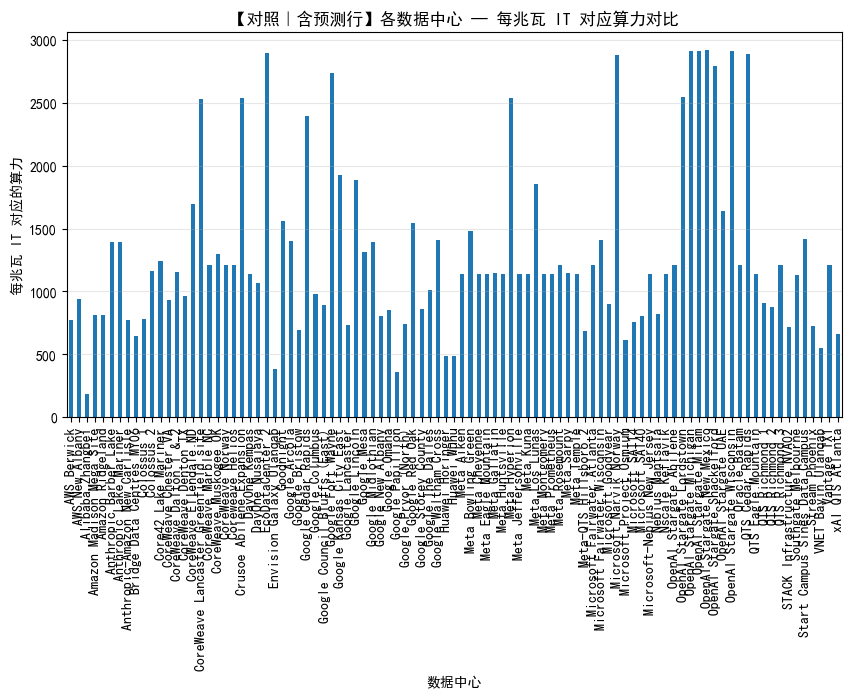

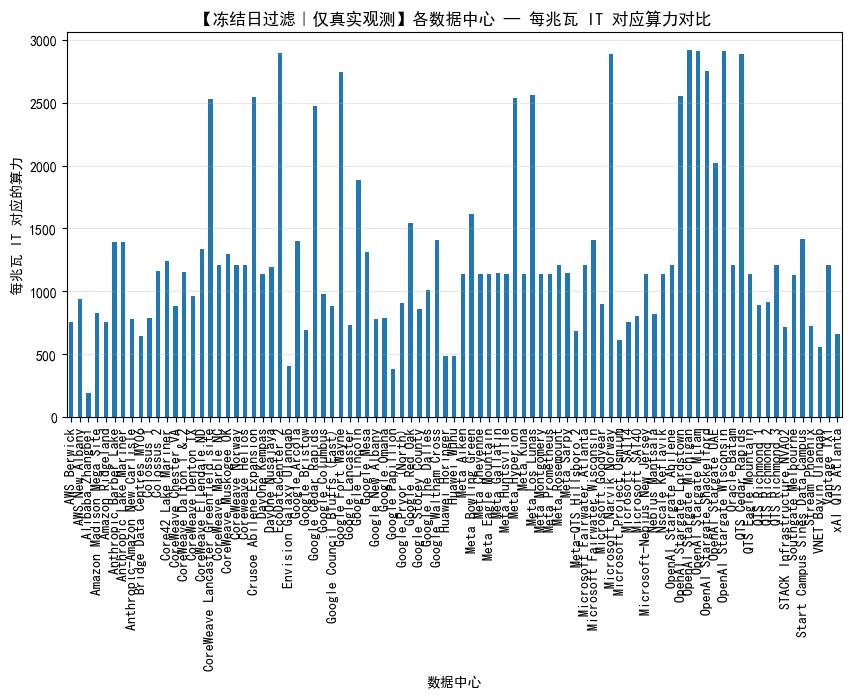

In [22]:
# ==========【对照｜含预测行】==========
# 创建画布，设置尺寸
plt.figure(figsize=(10, 5))
# 使用平均值绘制柱状图
机房汇总["mean"].plot(kind="bar")
# X 轴标签
plt.xlabel("数据中心")
# Y 轴标签
plt.ylabel("每兆瓦 IT 对应的算力")
# 图标题
plt.title("【对照｜含预测行】各数据中心 — 每兆瓦 IT 对应算力对比")
# 横向网格，看着舒服
plt.grid(axis="y", alpha=0.3)
# 保存图片
plt.savefig("bar_dc_compare_with_proj.png", dpi=300, bbox_inches="tight")
# 展示图片
plt.show()


# ==========【正式｜冻结日过滤｜仅真实观测】新增 ==========
plt.figure(figsize=(10, 5))
机房汇总_actual["mean"].plot(kind="bar")
plt.xlabel("数据中心")
plt.ylabel("每兆瓦 IT 对应的算力")
plt.title("【冻结日过滤｜仅真实观测】各数据中心 — 每兆瓦 IT 对应算力对比")
plt.grid(axis="y", alpha=0.3)
plt.savefig("bar_dc_compare_actual.png", dpi=300, bbox_inches="tight")
plt.show()

丑，重做

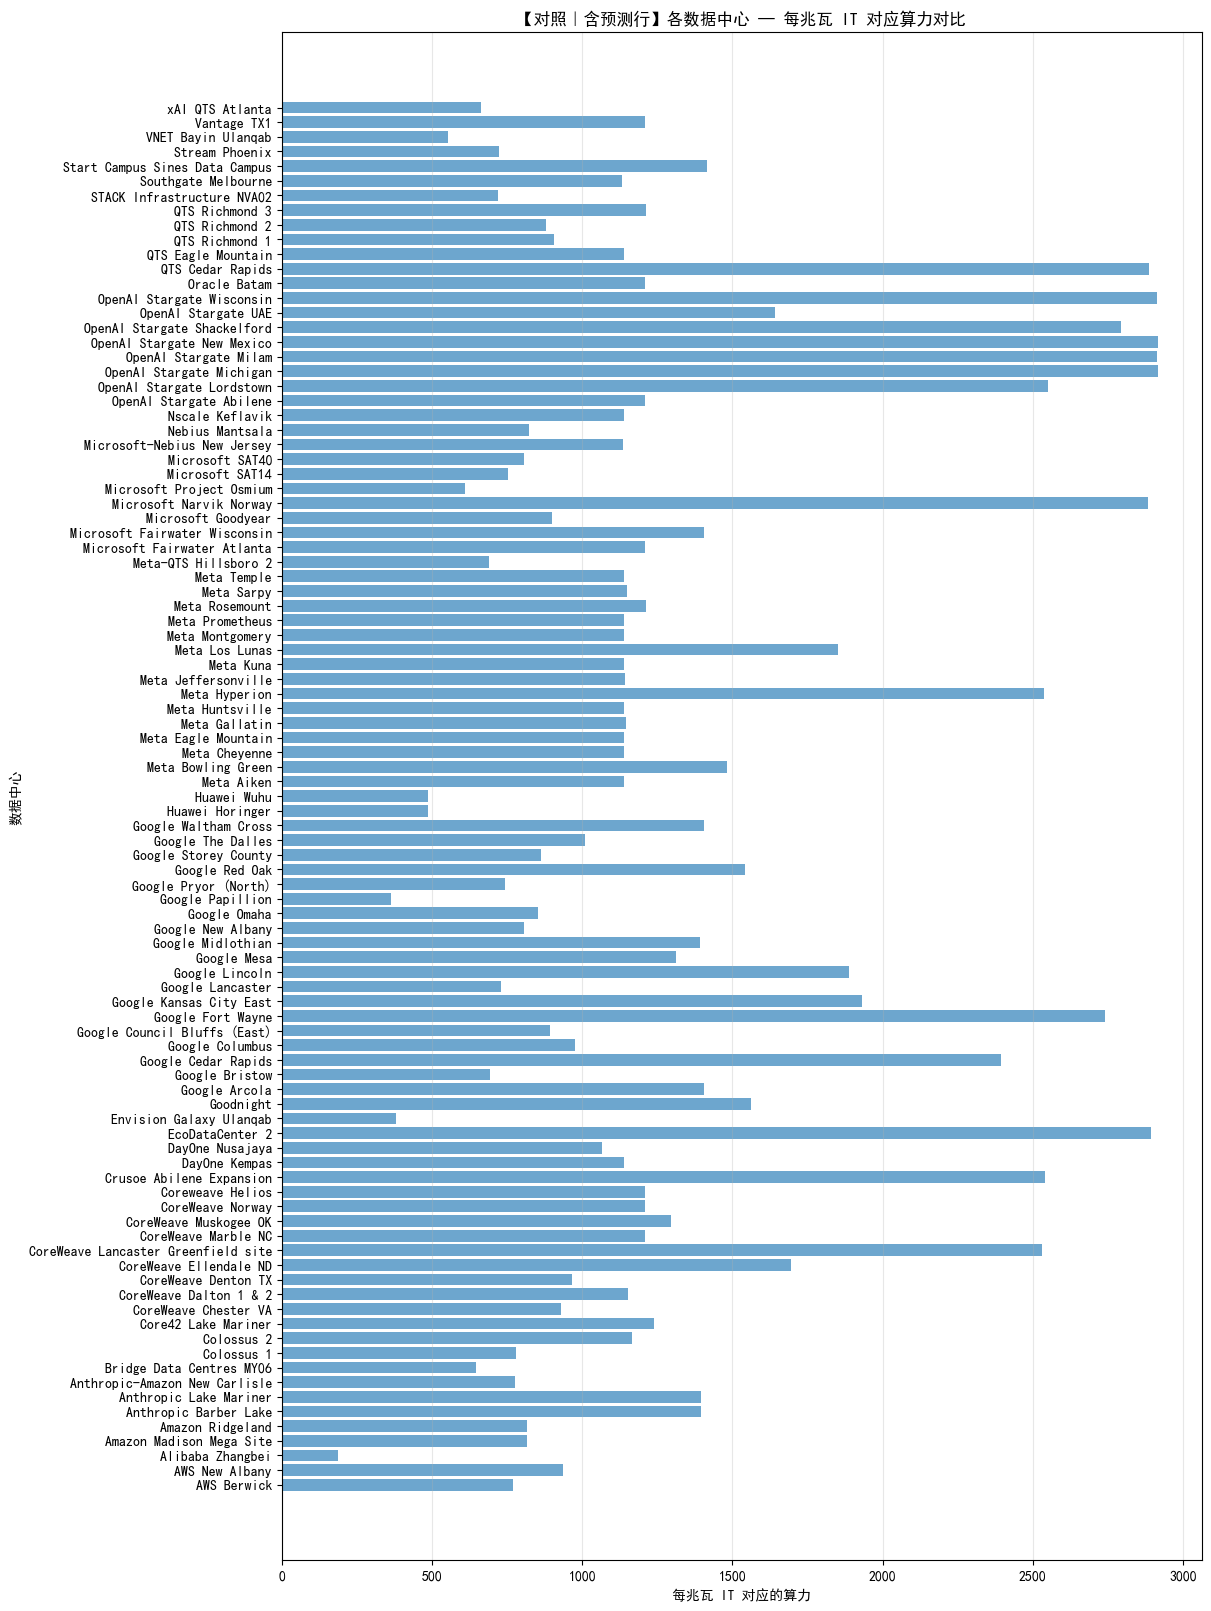

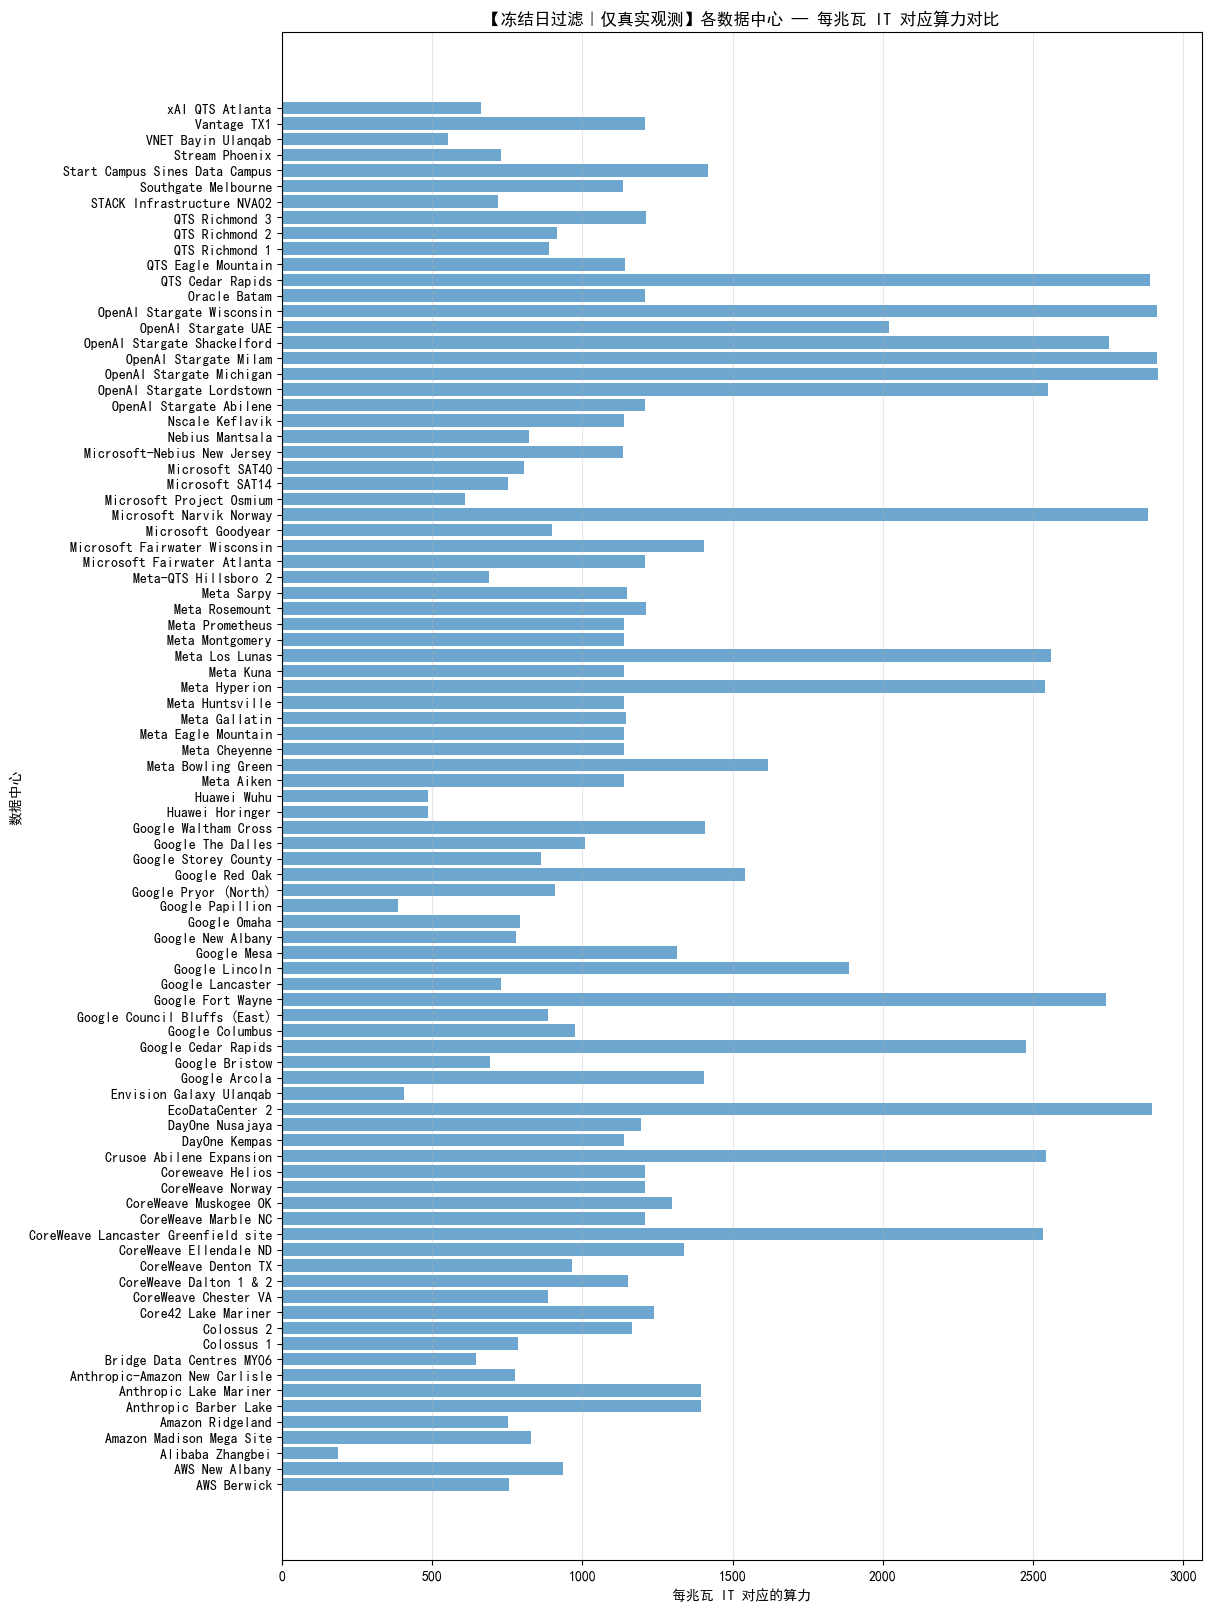

In [23]:
# ==========【对照｜含预测行】保留你的风格 ==========
# 创建画布，放大尺寸，自动排版防截断
plt.figure(figsize=(12, 16), constrained_layout=True)

# 横向柱状图
plt.barh(机房汇总.index, 机房汇总["mean"], alpha=0.65)

# 坐标轴、标题
plt.xlabel("每兆瓦 IT 对应的算力")
plt.ylabel("数据中心")
plt.title("【对照｜含预测行】各数据中心 — 每兆瓦 IT 对应算力对比")
plt.grid(axis="x", alpha=0.3)

# 保存图片
plt.savefig("dc_barh_with_proj.png", dpi=300)
plt.show()


# ==========【正式｜冻结日过滤｜仅真实观测】新增 ==========
plt.figure(figsize=(12, 16), constrained_layout=True)
plt.barh(机房汇总_actual.index, 机房汇总_actual["mean"], alpha=0.65)

plt.xlabel("每兆瓦 IT 对应的算力")
plt.ylabel("数据中心")
plt.title("【冻结日过滤｜仅真实观测】各数据中心 — 每兆瓦 IT 对应算力对比")
plt.grid(axis="x", alpha=0.3)

plt.savefig("dc_barh_actual.png", dpi=300)
plt.show()

再加个排序，从长到短排

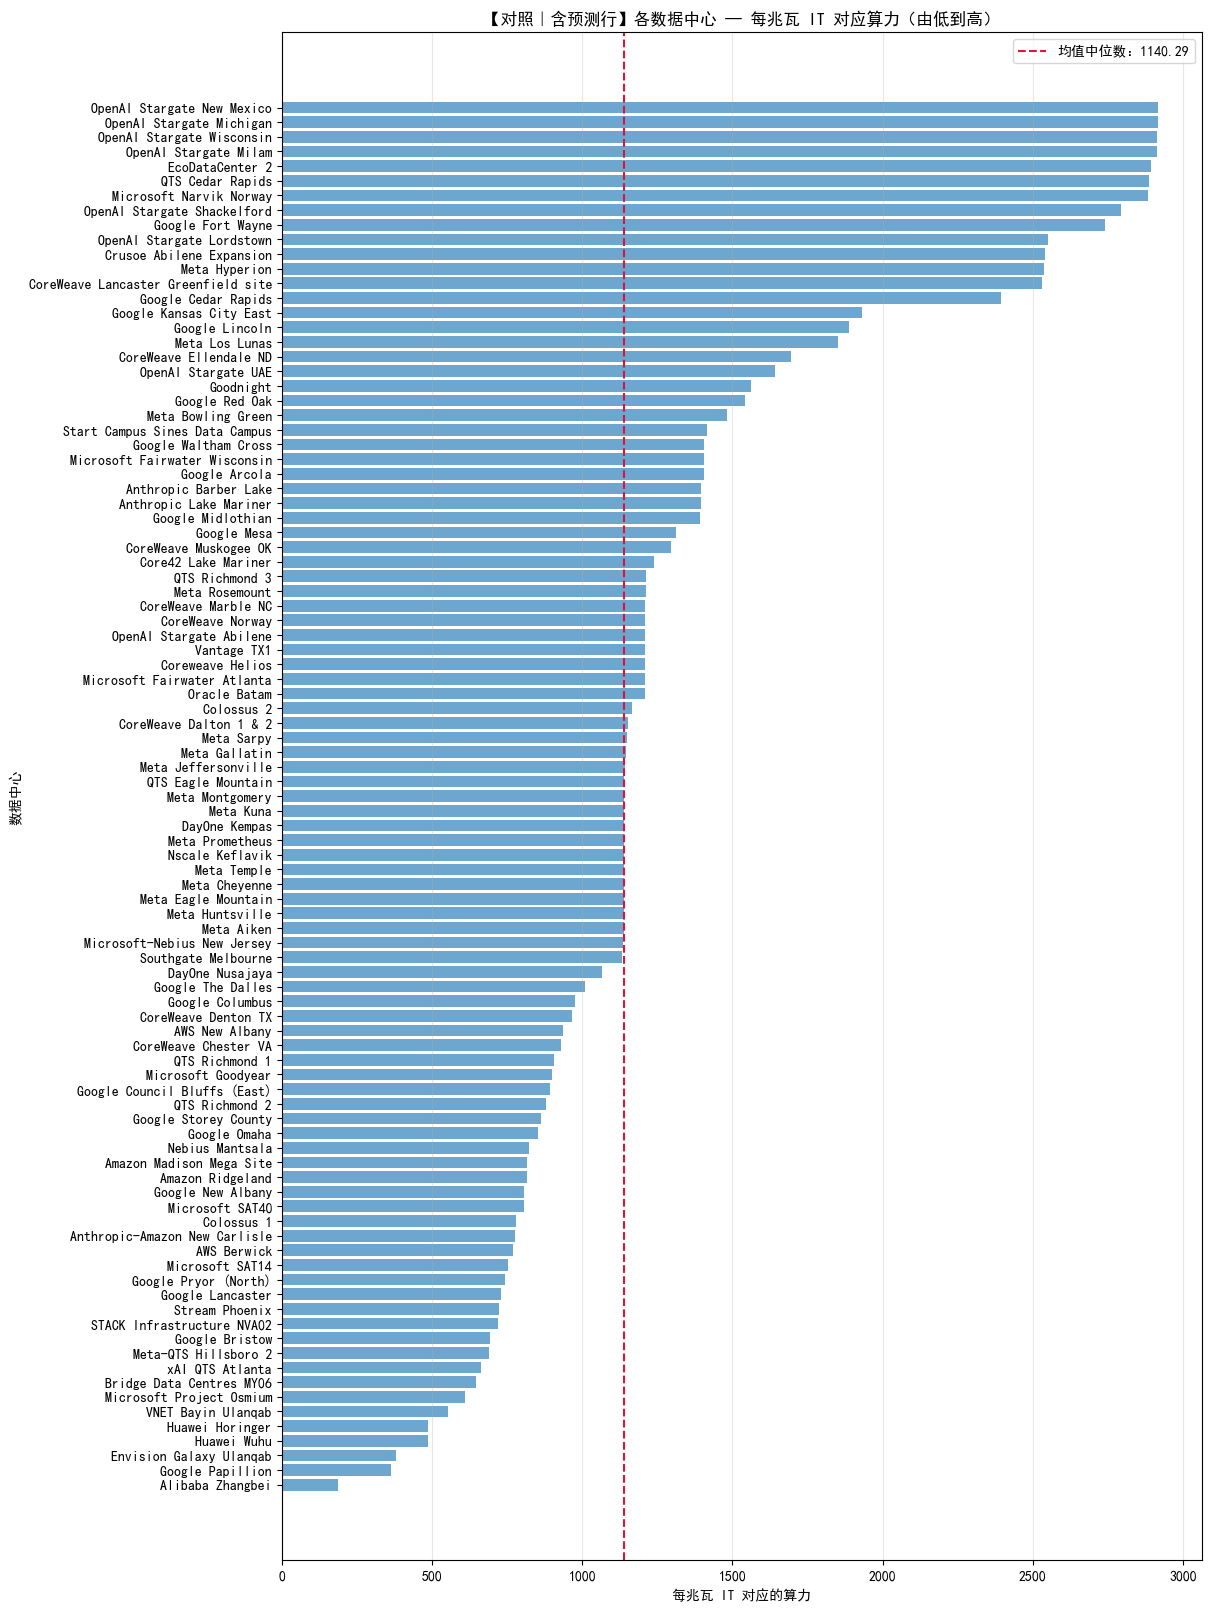

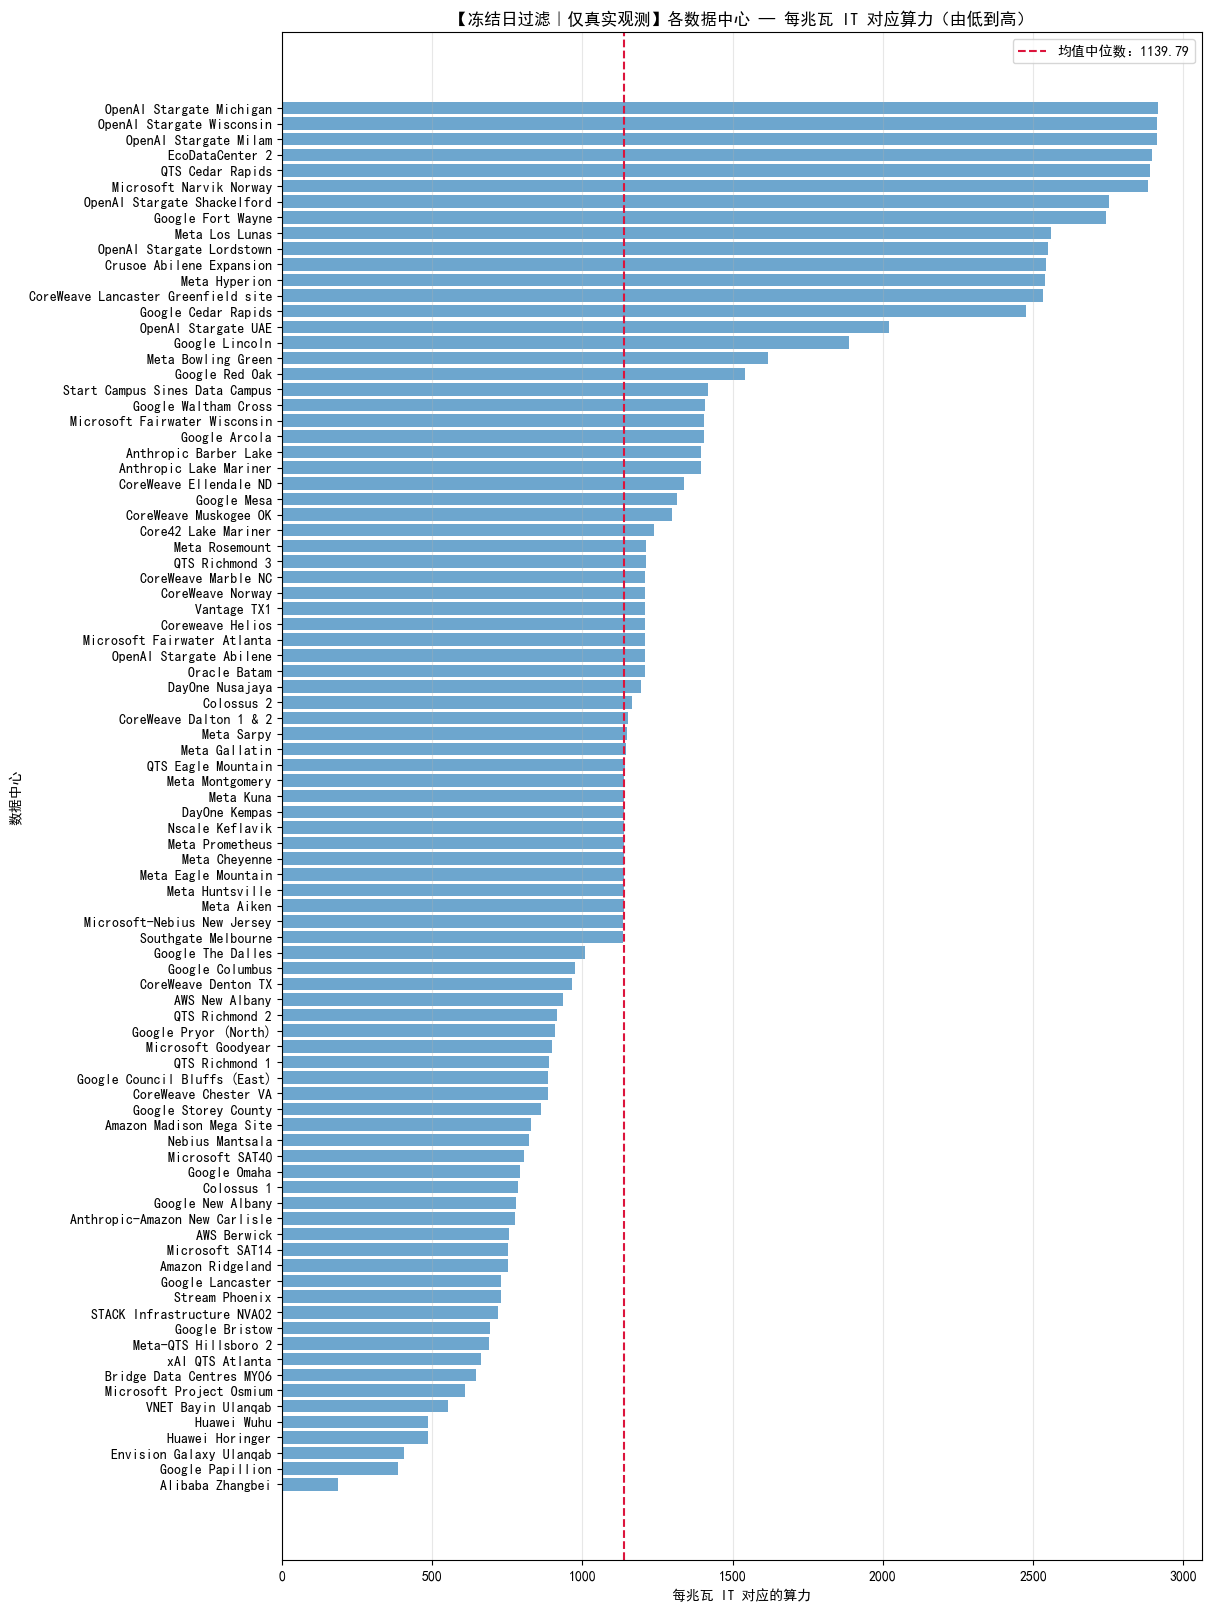

In [24]:
# ==========【对照｜含预测行】==========
# 按均值降序排序（ascending=True → 由低到高）
机房汇总排序 = 机房汇总.sort_values("mean", ascending=True)
median_val = 机房汇总排序["mean"].median()

# 创建画布
plt.figure(figsize=(12, 16), constrained_layout=True)
plt.barh(机房汇总排序.index, 机房汇总排序["mean"], alpha=0.65)

# 添加中位线
plt.axvline(x=median_val, color="crimson", linestyle="--", label=f"均值中位数：{median_val:.2f}")

plt.xlabel("每兆瓦 IT 对应的算力")
plt.ylabel("数据中心")
plt.title("【对照｜含预测行】各数据中心 — 每兆瓦 IT 对应算力（由低到高）")
plt.grid(axis="x", alpha=0.3)
plt.legend()

plt.savefig("dc_sorted_with_proj.png", dpi=300)
plt.show()


# ==========【正式｜冻结日过滤｜仅真实观测】==========
机房汇总_actual排序 = 机房汇总_actual.sort_values("mean", ascending=True)
median_actual = 机房汇总_actual排序["mean"].median()

plt.figure(figsize=(12, 16), constrained_layout=True)
plt.barh(机房汇总_actual排序.index, 机房汇总_actual排序["mean"], alpha=0.65)
plt.axvline(x=median_actual, color="crimson", linestyle="--", label=f"均值中位数：{median_actual:.2f}")

plt.xlabel("每兆瓦 IT 对应的算力")
plt.ylabel("数据中心")
plt.title("【冻结日过滤｜仅真实观测】各数据中心 — 每兆瓦 IT 对应算力（由低到高）")
plt.grid(axis="x", alpha=0.3)
plt.legend()

plt.savefig("dc_sorted_actual.png", dpi=300)
plt.show()

图：各数据中心每兆瓦 IT 对应算力（冻结日过滤，仅真实观测，按中位数排序）。
图中红色虚线为整体中位数，可区分高低梯队；多数站点样本仅 2–7 条，少量站点样本偏少，观测结果仅作参考，不宜直接判定为长期稳态。

为规避部分站点样本少带来的均值陷阱，进一步使用各数据中心观测中位数进行对比。下图为按中位数排序的横向柱状图。

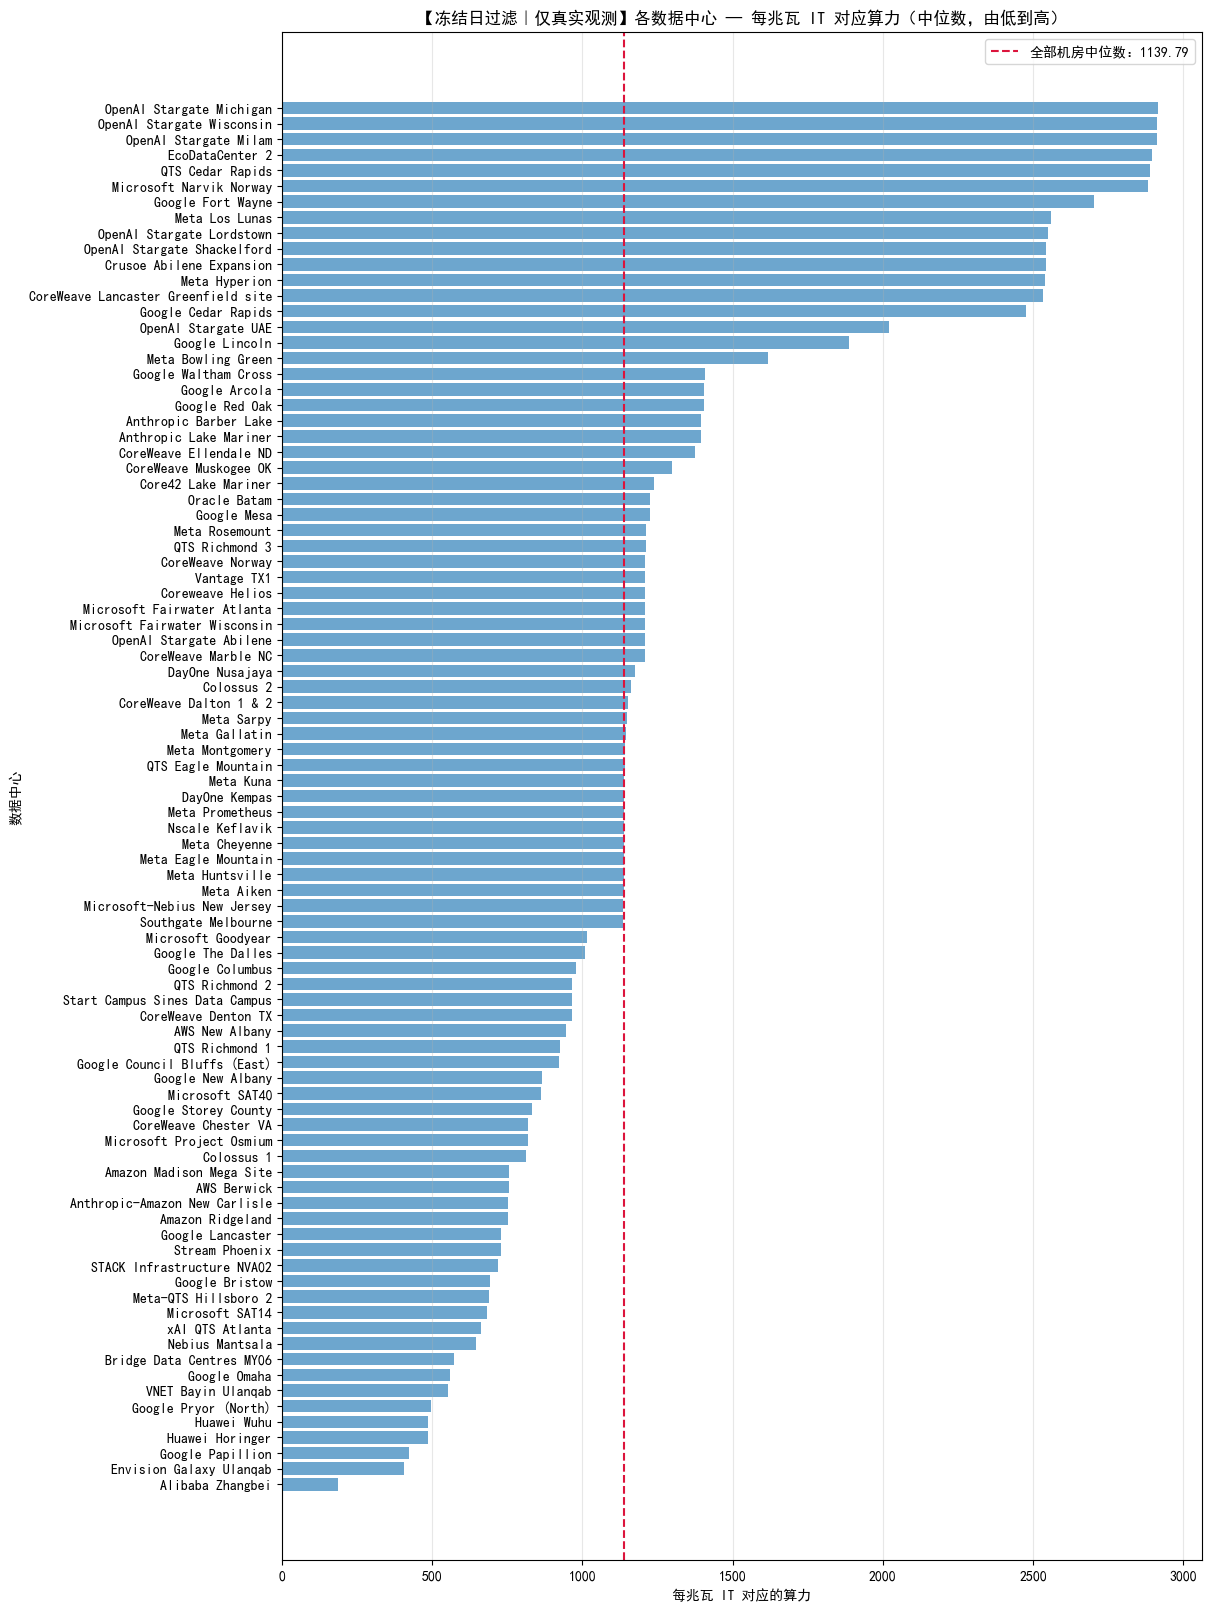

In [30]:
# 计算每个机房的中位数
机房汇总_actual = df_actual_full.groupby("Data center")["每兆瓦 IT 对应算力"].agg(["count", "median"])

# 按中位数由低到高排序
机房汇总_median_sort = 机房汇总_actual.sort_values("median", ascending=True)

plt.figure(figsize=(12, 16), constrained_layout=True)
plt.barh(机房汇总_median_sort.index,
         机房汇总_median_sort["median"],
         alpha=0.65)

# 全部机房的中位数红线
整体中位数 = 机房汇总_median_sort["median"].median()
plt.axvline(x = 整体中位数, color = "crimson", linestyle = "--", label = f"全部机房中位数：{整体中位数:.2f}")

plt.xlabel("每兆瓦 IT 对应的算力")
plt.ylabel("数据中心")
plt.title("【冻结日过滤｜仅真实观测】各数据中心 — 每兆瓦 IT 对应算力（中位数，由低到高）")
plt.grid(axis = "x", alpha = 0.3)
plt.legend()

plt.savefig("dc_barh_median_actual.png", dpi = 300)
plt.show()

图：【冻结日过滤｜仅真实观测】各数据中心每兆瓦 IT 对应算力（中位数，由低到高）。红色虚线为全部机房中位数。多数站点样本仅 2–7 条，少量站点样本偏少，结果仅为观测参考，不代表长期稳态水平。

### 不同数据中心对比分析：单位 IT 功率对应的算力
指标：每兆瓦 IT 对应算力（H100 equivalents / IT power (MW)）
- 观测结果：采用中位数后，缓解少数极端观测对机房整体水平的扰动；不同数据中心单位IT功率承载算力依然存在明显差异，说明机房硬件配置、运行模式之间确实存在区别。
- 业务解读：在同样 IT 硬件投入下，不同数据中心能够承载的算力并不一致，反映各机房硬件配置、集群调度方案存在区别。
- 局限：大部分数据中心样本数量偏少（多为 2–7 条），结论需要谨慎，不能过度泛化。

## 九、IT 功率与数据中心总功率分析
> 研究目标：对比 IT 硬件功率与数据中心总功率，借助 PUE 观察制冷、配电等配套基础设施带来的额外能耗，探究数据中心扩容时总能耗的变化规律。

### 指标说明
- **IT power (MW)**：IT 硬件功率，代表算力设备本身的耗电；
- **Power (MW)**：数据中心总功率，包含算力设备以及制冷、配电等配套设施；
- **PUE**：电源使用效率，$\text{pue} = \dfrac{\text{总功率}}{\text{IT 硬件功率}}$，用来衡量配套基础设施的能耗开销。

### 数据说明
沿用清洗后的 `df_full`，一方面按数据中心分组统计IT 功率、总功率、PUE 各项指标均值；另一方面绘制散点图，观察二者之间的变化关系。多数数据中心样本量偏少，解读结论时需要保持谨慎。

In [25]:
# ==========【对照｜含预测行】保留你的代码 ==========
# 按数据中心分组，求 IT 功率、总功率、PUE 的平均值
数据中心能耗汇总 = df_full.groupby("Data center")[["IT power (MW)", "Power (MW)", "pue"]].agg(["mean"])

# 打印结果
print("\n====【对照｜含预测行】各数据中心能耗与 PUE 均值 ====")
print(数据中心能耗汇总)


# ==========【正式｜冻结日过滤｜仅真实观测】新增 ==========
数据中心能耗汇总_actual = df_actual_full.groupby("Data center")[["IT power (MW)", "Power (MW)", "pue"]].agg(["count", "mean"])
print("\n" + "=" * 60)
print("====【冻结日过滤｜仅真实观测】各数据中心能耗与 PUE ====")
print(数据中心能耗汇总_actual)


====【对照｜含预测行】各数据中心能耗与 PUE 均值 ====
                               IT power (MW)  Power (MW)       pue
                                        mean        mean      mean
Data center                                                       
AWS Berwick                        92.500000  120.500000  1.319959
AWS New Albany                    219.250000  262.750000  1.199033
Alibaba Zhangbei                  113.000000  135.666667  1.200394
Amazon Madison Mega Site          363.800000  464.000000  1.296867
Amazon Ridgeland                  450.666667  540.666667  1.199358
...                                      ...         ...       ...
Start Campus Sines Data Campus     99.666667  120.000000  1.208653
Stream Phoenix                    142.000000  172.000000  1.208381
VNET Bayin Ulanqab                230.000000  262.000000  1.136925
Vantage TX1                        80.000000  112.000000  1.400000
xAI QTS Atlanta                    17.329710   24.000000  1.384905

[95 rows x 3 columns]

===

冻结过滤后，统计各数据中心 IT 硬件功率、总功率与 PUE；可以观察到不同机房电源使用效率存在差异，VNET Bayin Ulanqab 的平均 PUE 偏低，Vantage TX1 平均 PUE 偏高。部分机房样本量很小（如 Stream Phoenix，仅 1 条），结果仅作参考。

In [26]:
# 单独提取 pue 那一列
pue_序列 = 数据中心能耗汇总["pue"]["mean"]

# 找最小、最大
pue_min = pue_序列.idxmin(), pue_序列.min()
pue_max = pue_序列.idxmax(), pue_序列.max()

print("✅ PUE 最小：", pue_min)
print("✅ PUE 最大：", pue_max)

# ==========【正式｜冻结日过滤｜仅真实观测】==========
# 提取 pue 均值序列
pue_序列_actual = 数据中心能耗汇总_actual["pue"]["mean"]
pue_min_actual = pue_序列_actual.idxmin(), pue_序列_actual.min()
pue_max_actual = pue_序列_actual.idxmax(), pue_序列_actual.max()

print("\n====【冻结日过滤｜仅真实观测】PUE 极值 + 样本量 ====")
print("PUE 最小机房：", pue_min_actual[0], "｜值：", f"{pue_min_actual[1]:.4f}")
print("PUE 最大机房：", pue_max_actual[0], "｜值：", f"{pue_max_actual[1]:.4f}")

# 取出这两行，自带 count
极值行 = 数据中心能耗汇总_actual.loc[[pue_min_actual[0], pue_max_actual[0]]]
print("\n==== 极值机房详细信息 ====")
print(极值行)


✅ PUE 最小： ('Core42 Lake Mariner', np.float64(1.09375))
✅ PUE 最大： ('Coreweave Helios', np.float64(1.515151515151515))

====【冻结日过滤｜仅真实观测】PUE 极值 + 样本量 ====
PUE 最小机房： Core42 Lake Mariner ｜值： 1.0938
PUE 最大机房： Coreweave Helios ｜值： 1.5152

==== 极值机房详细信息 ====
                    IT power (MW)        Power (MW)               pue  \
                            count   mean      count        mean count   
Data center                                                             
Core42 Lake Mariner             4   37.0          4   38.500000     4   
Coreweave Helios                3  352.0          3  533.333333     3   

                               
                         mean  
Data center                    
Core42 Lake Mariner  1.093750  
Coreweave Helios     1.515152  


在冻结过滤后的真实观测样本中，PUE 最低为 Core42 Lake Mariner（4 条记录，均值 1.09），配套能耗控制表现优秀；PUE 最高为 Coreweave Helios（3 条记录，均值 1.52），基础设施能耗开销相对更高。二者样本量都尚可，具备较好的参考价值。

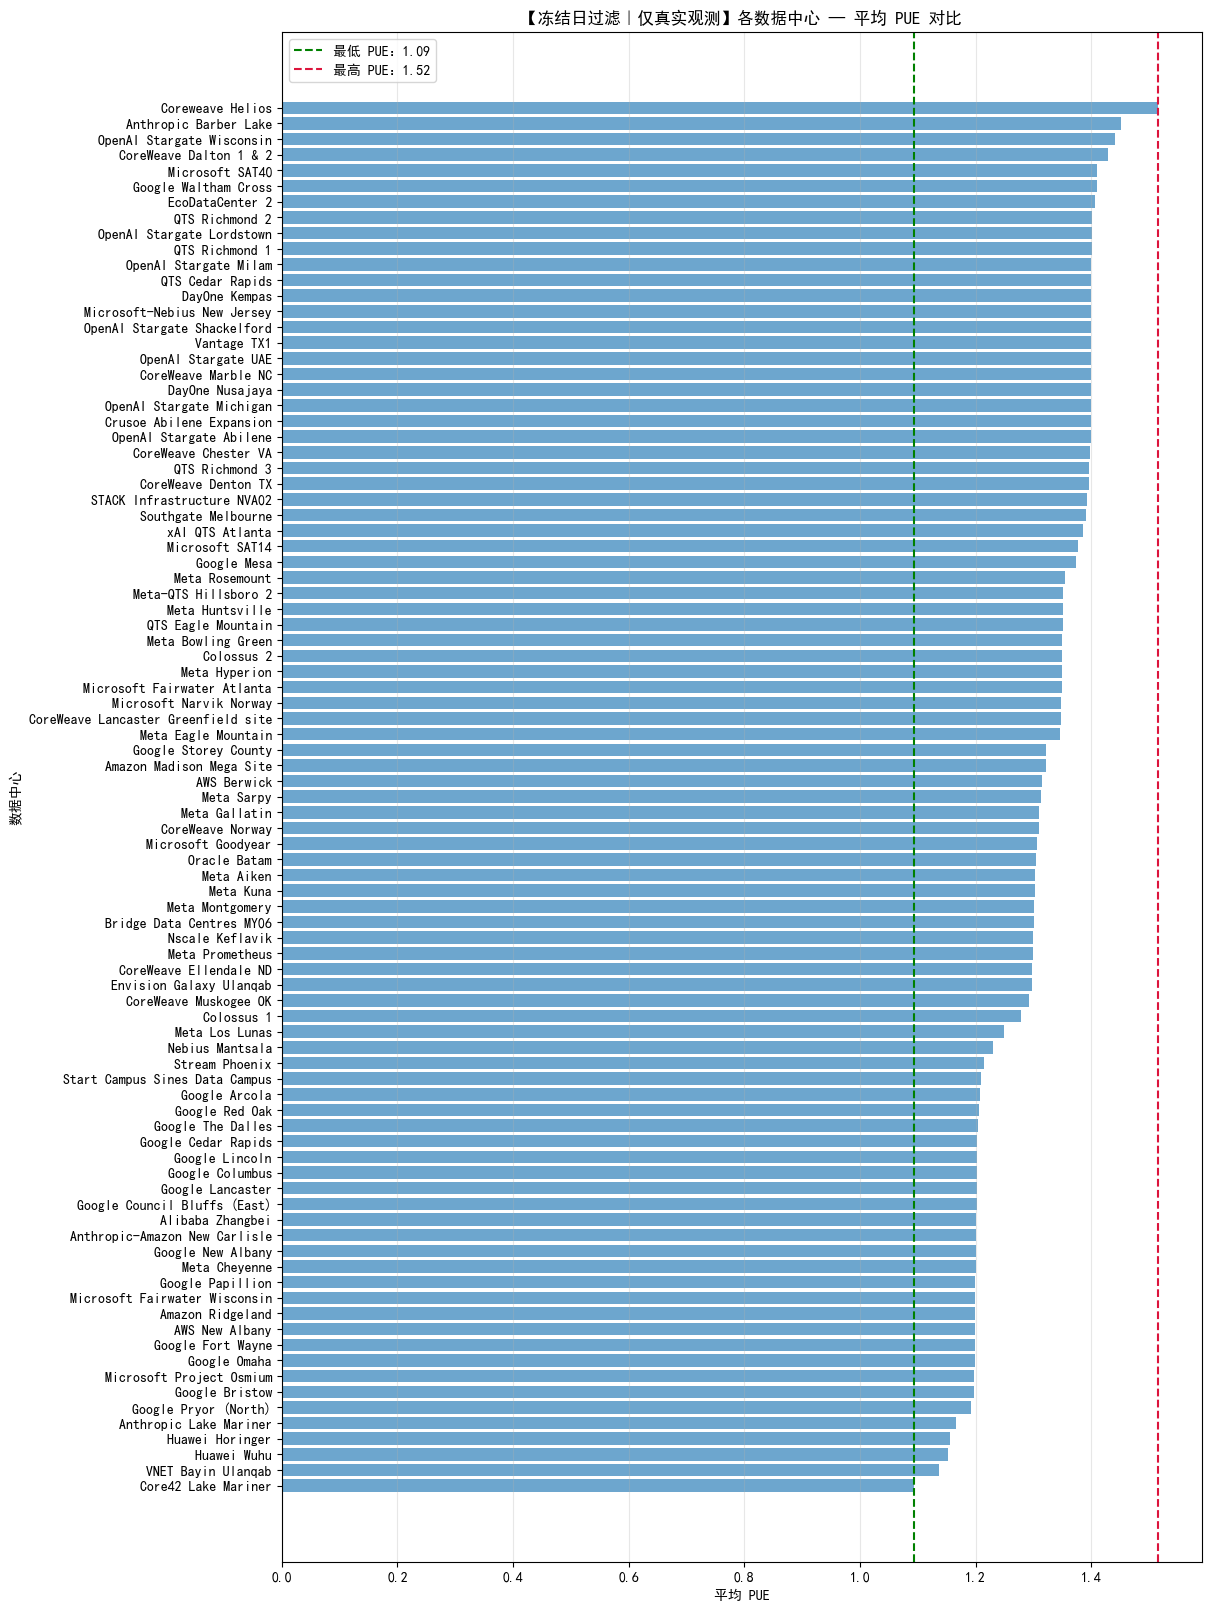

In [27]:
# ==========【正式｜冻结日过滤｜仅真实观测】==========
pue_sort = 数据中心能耗汇总_actual.sort_values(("pue", "mean"), ascending=True)

plt.figure(figsize=(12,16), constrained_layout=True)
plt.barh(pue_sort.index, pue_sort[("pue", "mean")], alpha=0.65)

# 标记最大最小
plt.axvline(x = 1.09375, color = "green", linestyle = "--", label = f"最低 PUE：1.09")
plt.axvline(x = 1.515152, color = "crimson", linestyle = "--", label = f"最高 PUE：1.52")

plt.xlabel("平均 PUE")
plt.ylabel("数据中心")
plt.title("【冻结日过滤｜仅真实观测】各数据中心 — 平均 PUE 对比")
plt.grid(axis = "x", alpha = 0.3)
plt.legend()
plt.savefig("barh_pue_actual.png", dpi = 300)
plt.show()


图：各数据中心平均 PUE 对比（冻结日过滤，仅真实观测）
 
可以看到不同数据中心电源使用效率存在明显跨度：
 
​
- Core42 Lake Mariner，4 条记录，平均 PUE = 1.09，配套能耗控制优秀；
​
- Coreweave Helios，3 条记录，平均 PUE = 1.52，基础设施能耗开销相对更高；
​
- 其余大量机房落在中间区间。
 
注意：少量机房样本仅 1～2 条，其均值仅为观测结果，不宜当成长期稳定水平。

### PUE 统计结果
按数据中心分组，统计 IT 功率均值、总功率均值以及 PUE 均值：
- 各数据中心 PUE 差异明显：最小值为 Core42 Lake Mariner 的 1.09，最大值为 Coreweave Helios 的 1.52；多数数据中心 PUE 集中在 1.20～1.32。
- 业务解读：PUE 衡量制冷、配电等配套基础设施的能耗开销；PUE 越接近 1，配套能耗控制效果越好。
- 局限：大部分数据中心样本数量偏少，结论需要谨慎，不宜过度泛化。


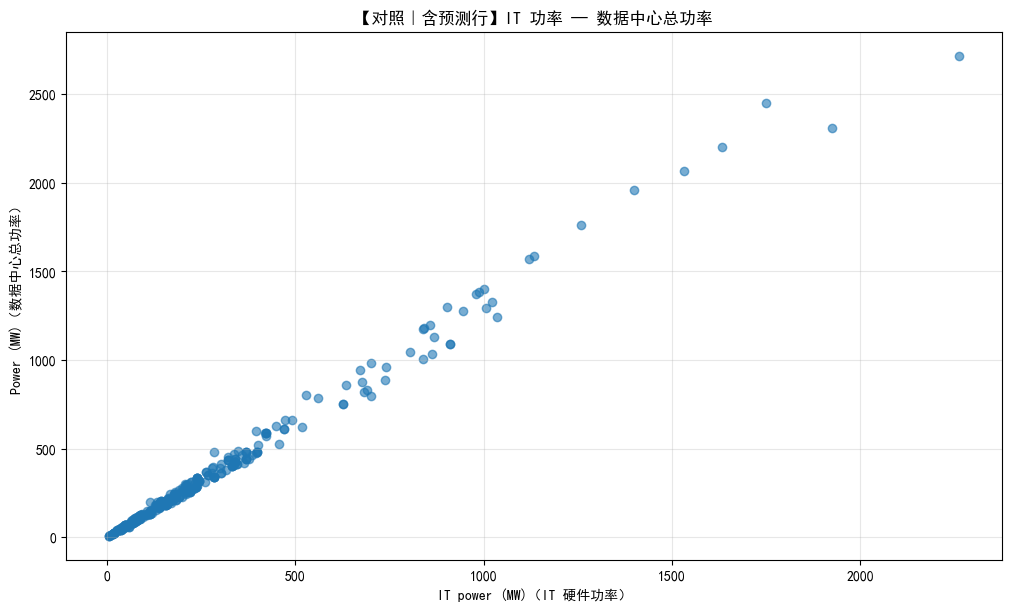

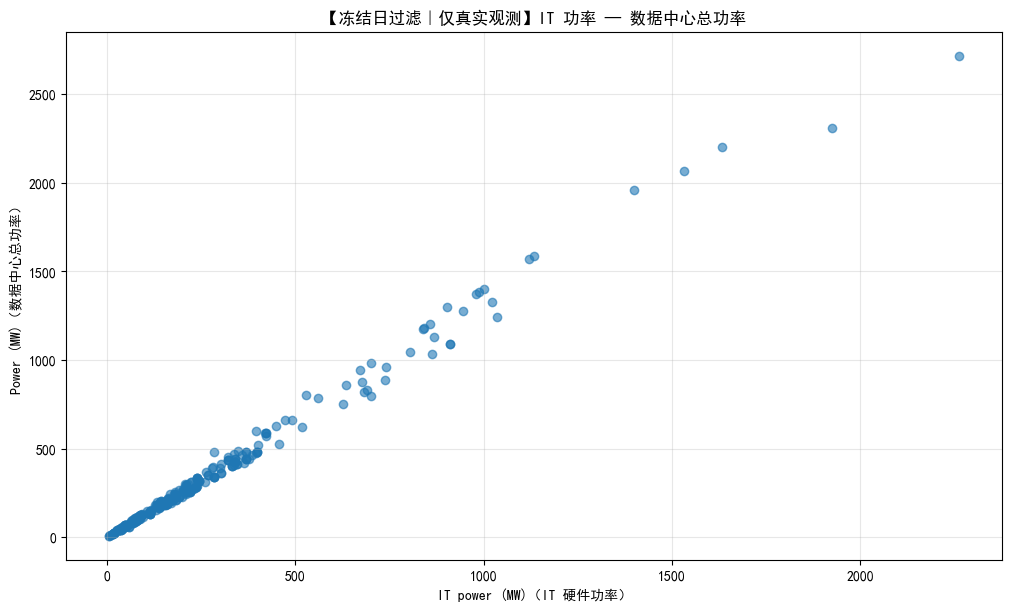

In [28]:
# ==========【对照｜含预测行】保留你的代码 ==========
# 创建画布，设置尺寸
plt.figure(figsize=(10, 6), constrained_layout=True)
# 绘制散点：IT 硬件功率 vs 数据中心总功率
plt.scatter(df_full["IT power (MW)"], df_full["Power (MW)"], alpha=0.6)

# 设置坐标轴与标题
plt.xlabel("IT power (MW)（IT 硬件功率）")
plt.ylabel("Power (MW)（数据中心总功率）")
plt.title("【对照｜含预测行】IT 功率 — 数据中心总功率")
plt.grid(alpha=0.3)

# 保存图片
plt.savefig("scatter_it_total_with_proj.png", dpi=300)
plt.show()


# ==========【正式｜冻结日过滤｜仅真实观测】新增 ==========
plt.figure(figsize=(10, 6), constrained_layout=True)
plt.scatter(df_actual_full["IT power (MW)"], df_actual_full["Power (MW)"], alpha=0.6)

plt.xlabel("IT power (MW)（IT 硬件功率）")
plt.ylabel("Power (MW)（数据中心总功率）")
plt.title("【冻结日过滤｜仅真实观测】IT 功率 — 数据中心总功率")
plt.grid(alpha=0.3)

plt.savefig("scatter_it_total_actual.png", dpi=300)
plt.show()

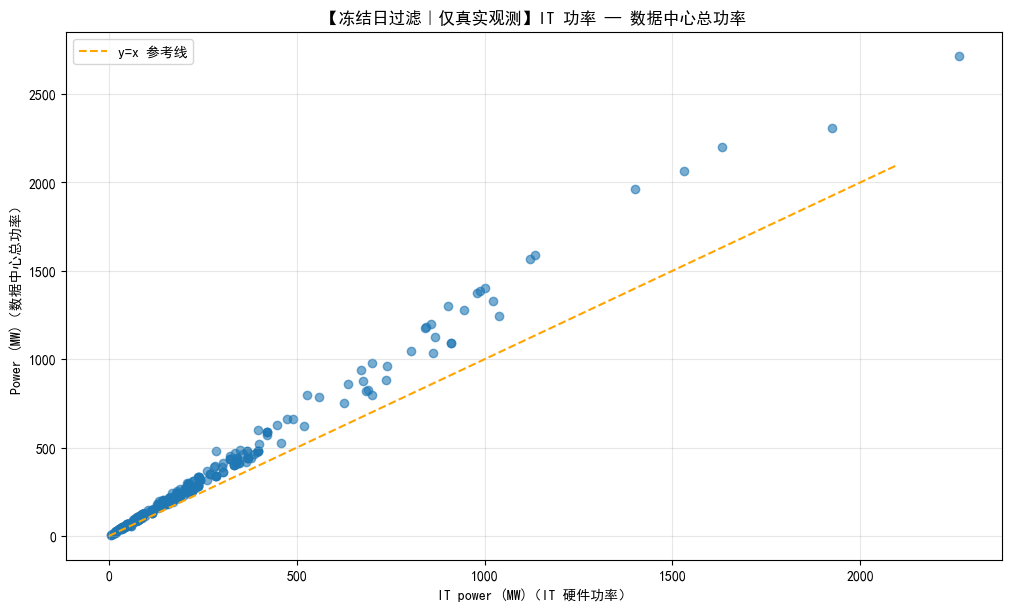

In [29]:
plt.figure(figsize=(10, 6), constrained_layout=True)
plt.scatter(df_actual_full["IT power (MW)"], df_actual_full["Power (MW)"], alpha=0.6)
plt.plot([0, 2100], [0, 2100], color="orange", linestyle="--", label="y=x 参考线")
plt.xlabel("IT power (MW)（IT 硬件功率）")
plt.ylabel("Power (MW)（数据中心总功率）")
plt.title("【冻结日过滤｜仅真实观测】IT 功率 — 数据中心总功率")
plt.grid(alpha=0.3)
plt.legend()
plt.savefig("scatter_it_total_ref_actual.png", dpi=300)
plt.show()

> 橙线含义：
> - 线上：总功率 = IT 功率
> - 线上方：总功率更大，多出部分为制冷、配电等配套能耗

### IT 功率与数据中心总功率关系
绘制散点图观察 IT 硬件功率与数据中心总功率：
- 整体呈现明显正相关：随着 IT 功率上升，数据中心总功率同步增长。
- 结合前面的 PUE 结果：在相同 IT 功率水平下，总功率存在一定浮动，反映各数据中心制冷、配电等配套基础设施能耗控制水平不同。
- 局限：少量高负载观测点以及各数据中心样本量不均衡，结论不宜过度外推。

## 十、 基于历史观测的未来电力需求预测

在完成对已投运数据中心 IT 功率、总功率、PUE 以及算力与功率关系分析之后，本节使用剔除预测规划行的真实观测样本，计算能效指标的中位数作为基准，对 2027–2030 承诺新增算力开展基准情景电力需求预测。

本预测分为三步开展：
 1. 使用剔除规划预测样本、仅保留已投运机房的数据集 df_actual_full ，计算得到现实条件下两套能效指标的中位数，作为基准，代表每兆瓦电力能够承载的等效H100算力；
2. 设置情景假设：2027‑2030拟新增48 000 000等效H100算力；
3. 通过算力除以单位功率算力的方式，反推实现该算力规模所需要的IT硬件功率以及包含制冷配电损耗在内的机房总供电功率。
 
⚠️该预测属于what‑if情景分析，假设未来新建机房能效分布与当前已投运样本保持一致，并非确定性预测。

预测输入： 2027‑2030 承诺新增 \boldsymbol{48\,000\,000} 等效 H100（48.0 M H100e）。
 
- \mathit{eff}_{it}：IT 硬件口径能效，每兆瓦 IT 硬件功率承载等效 H100 算力；仅包含服务器、GPU 硬件耗电，不含制冷、配电损耗。
- \mathit{eff}_{total}：机房总功率口径能效，每兆瓦机房总功率承载等效 H100 算力；纳入制冷、配电配套损耗，更贴近向电网获取的供电规模。
 
计算公式：

IT\_power_{add}= \frac{H_{add}}{eff_{it}},\quad Power_{add}= \frac{H_{add}}{eff_{total}} 

In [31]:
import pandas as pd
# 步骤1：拿真实投运机房，算出能效基准（每MW承载多少H100e）
# 读剔除预测行的真实数据
df_actual_full = pd.read_csv("timeline_cleaned_actual.csv", encoding="utf-8-sig")

# 求两个能效中位数
med_eff_it = df_actual_full["eff_it"].median()   # 每1 MW IT硬件功率可以扛多少H100e
med_eff_total = df_actual_full["eff_total"].median()  # 每1 MW机房总供电（IT+制冷配电）可以扛多少H100e

# 步骤2：人为设定未来扩张目标（what‑if情景假设）
# 给定新增算力
H_add = 48.0 * 10**6

# 步骤3：反推电力需要多少兆瓦
# 公式：\text{所需功率} = \dfrac{\text{目标总算力}}{\text{每兆瓦可承载算力}}
# 计算
add_it_power_mw = H_add / med_eff_it # IT硬件本身耗电
add_total_power_mw = H_add / med_eff_total # 整套机房向电网取电，含制冷配电损耗（总用电需求）

# 打印结果
print("===== 预测结果 =====")
print(f"eff_it 中位数：{med_eff_it:.2f}  H100e / MW‑IT")
print(f"eff_total 中位数：{med_eff_total:.2f} H100e / MW‑总功率")
print(f"\n承诺新增等效 H100：{H_add:,}")
print(f"👉 仅 IT 硬件功率：{add_it_power_mw:.2f} MW")
print(f"👉 机房总供电功率：{add_total_power_mw:.2f} MW")

# 保存结果
pred_result = pd.DataFrame({
    "项目": [
        "承诺新增 H100e",
        "eff_it 中位数",
        "eff_total 中位数",
        "新增 IT 功率(MW)",
        "新增总功率(MW)"
    ],
    "数值": [
        H_add,
        med_eff_it,
        med_eff_total,
        add_it_power_mw,
        add_total_power_mw
    ]
})
pred_result.to_csv("power_prediction_local.csv", index=False, encoding="utf-8-sig")
print("\n✅ 结果保存为：power_prediction_local.csv")

===== 预测结果 =====
eff_it 中位数：1019.10  H100e / MW‑IT
eff_total 中位数：797.76 H100e / MW‑总功率

承诺新增等效 H100：48,000,000.0
👉 仅 IT 硬件功率：47100.20 MW
👉 机房总供电功率：60168.56 MW

✅ 结果保存为：power_prediction_local.csv


简单解读：
要新增4800万等效H100算力：
 
1. GPU服务器硬件本身就需要 47100.20 MW 的IT功率；
2. 算上制冷、配电损耗，从电网要获取总电力达到 60168.56 MW，多出的部分全部是配套基础设施能耗。
  
|项目|数值|
| ---- | ---- |
|情景假设：2027‑2030拟新增等效 H100e|48 000 000|
|历史观测中位数 $\mathit{eff}_{it}$|1019.10 H100e/MW‑IT|
|历史观测中位数 $\mathit{eff}_{total}$|797.76 H100e/MW‑总功率|
|预测新增 IT 硬件功率（仅 GPU 服务器）|47100.20 MW|
|预测机房总供电功率（含制冷配电损耗）|60168.56 MW|

> 注：48 000 000等效H100（48.0 M H100e）为本研究设置的what‑if未来情景假设，代表2027‑2030拟新增算力规模，并非历史已建成观测数据。H100e为Epoch数据集等效算力单位，将不同GPU统一折算为H100作为基准。本预测基于假想算力规模，结合已投运机房能效中位数反推电力需求。
 
结果解读
在本基准情景之下，如果要实现2027‑2030年新增4800万等效H100的算力扩张，仅GPU服务器硬件就需要47100.20 MW IT功率；叠加制冷、配电等基础设施损耗，数据中心整体需要从电网获取60168.56 MW总供电功率，可见AI算力扩张会带来非常可观的电力资源压力。
 
预测局限性
 
1. 本结果属于基准情景外推，核心假设为未来新建数据中心能效分布与当前已投运机房样本保持一致。
2. 若未来GPU芯片硬件能效进一步提升，或者新建数据中心PUE持续优化下降，实际电力需求会低于本次预测；反之，若新建机房运行能效较差，实际用电需求会更高。
3. 本分析仅依靠算力‑功率统计关系完成估算，未考虑电网建设时序、负荷波动、工程冗余备份等现实工程因素，仅作为课题情景分析参考，不等同实际工程规划方案。
- 补充局限：样本检验发现，机房算力规模与两套能效指标存在明显正相关（$r=0.672,\;r=0.656$），存在规模效应。本预测直接采用全样本中位数，没有按规模分层；如果未来新建机房以大规模机房为主，实际电力需求有可能低于当前基准预测。

## 十一、规模效应检验

In [33]:
import pandas as pd
df_actual_full = pd.read_csv("timeline_cleaned_actual.csv", encoding="utf-8-sig")
print("全部列名：")
print(df_actual_full.columns.tolist())


全部列名：
['Data center', 'Date', 'Construction status', 'Buildings operational', 'IT power (MW)', 'Power (MW)', 'H100 equivalents', 'Performance (8-bit OP/s)', 'Total capital cost (2025 USD billions)', 'Compute cost (2025 USD billions)', 'Construction cost (2025 USD billions)', 'Annual operating cost (2025 USD billions)', 'Water use (MGD)', 'Current H100 equivalents (from Data center)', 'is_projection', 'eff_total', 'eff_it', 'pue']


==== 规模效应检验：算力规模 — 能效相关系数 ====
算力规模 — eff_it 相关系数：0.672
算力规模 — eff_total 相关系数：0.656


C:\Users\陈永翾\AppData\Local\Temp\ipykernel_17352\2512158160.py:31: UserWarning: Glyph 8209 (\N{NON-BREAKING HYPHEN}) missing from font(s) SimHei.
  plt.tight_layout()
C:\Users\陈永翾\AppData\Local\Temp\ipykernel_17352\2512158160.py:32: UserWarning: Glyph 8209 (\N{NON-BREAKING HYPHEN}) missing from font(s) SimHei.
  plt.savefig("scale_efficiency_scatter.png", dpi=300)
C:\Users\陈永翾\AppData\Local\Programs\Python\Python313\Lib\site-packages\IPython\core\pylabtools.py:158: UserWarning: Glyph 8209 (\N{NON-BREAKING HYPHEN}) missing from font(s) SimHei.
  fig.canvas.print_figure(bytes_io, **kw)


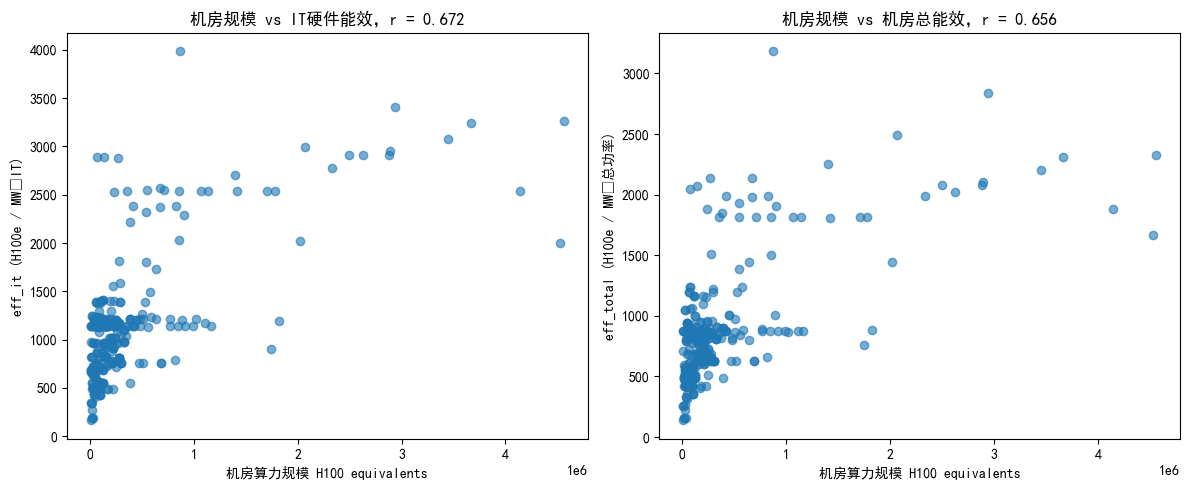


✅ 图表已保存：scale_efficiency_scatter.png


In [34]:
import pandas as pd
import matplotlib.pyplot as plt

# 使用与电力预测完全一致的清洗后数据集（仅真实投运样本，剔除projection）
df_actual_full = pd.read_csv("timeline_cleaned_actual.csv", encoding="utf-8-sig")

# 自变量：机房算力规模
size_col = "H100 equivalents"

# 计算皮尔逊相关系数
corr_size_effit = df_actual_full[[size_col, "eff_it"]].corr().iloc[0, 1]
corr_size_efftotal = df_actual_full[[size_col, "eff_total"]].corr().iloc[0, 1]

print("==== 规模效应检验：算力规模 — 能效相关系数 ====")
print(f"算力规模 — eff_it 相关系数：{corr_size_effit:.3f}")
print(f"算力规模 — eff_total 相关系数：{corr_size_efftotal:.3f}")

# 绘制并排散点图
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5))

ax1.scatter(df_actual_full[size_col], df_actual_full["eff_it"], alpha=0.6)
ax1.set_xlabel("机房算力规模 H100 equivalents")
ax1.set_ylabel("eff_it (H100e / MW‑IT)")
ax1.set_title(f"机房规模 vs IT硬件能效，r = {corr_size_effit:.3f}")

ax2.scatter(df_actual_full[size_col], df_actual_full["eff_total"], alpha=0.6)
ax2.set_xlabel("机房算力规模 H100 equivalents")
ax2.set_ylabel("eff_total (H100e / MW‑总功率)")
ax2.set_title(f"机房规模 vs 机房总能效，r = {corr_size_efftotal:.3f}")

plt.tight_layout()
plt.savefig("scale_efficiency_scatter.png", dpi=300)
plt.show()
print("\n✅ 图表已保存：scale_efficiency_scatter.png")


### 替代解释检验：机房规模效应检验

存在一种潜在替代解释：样本中能效差异可能来源于规模效应，大型数据中心天然具备更好的能源效率。
为验证该假设，基于已投运真实观测样本，以 `H100 equivalents` 表征机房总算力规模，计算机房算力规模与能效指标的皮尔逊相关系数，并绘制散点图。

![机房规模与能效散点](scale_efficiency_scatter.png)

- 算力规模与 $\mathit{eff}_{it}$ 皮尔逊相关系数：$\boldsymbol{0.672}$
- 算力规模与 $\mathit{eff}_{total}$ 皮尔逊相关系数：$\boldsymbol{0.656}$

结果显示二者存在明显正相关：**机房算力规模越大，能效倾向越高**，规模效应是不可忽视的因素。
这意味着直接使用全样本中位数做外推预测存在局限：当未来新建机房和样本的规模分布不一样时，预测结果会产生偏差。因此在预测部分补充该风险，说明本基准预测的适用边界。

全样本算力中位数(分组阈值): 155128.9 H100 equivalents
小规模组样本量: 150；大规模组样本量: 150

=====三情景预测结果======
        情景  eff_it_med  eff_total_med  IT_power_MW  Total_power_MW
0  保守(小规模)      754.68         579.61     63603.34        82814.31
1  基准(全样本)     1019.10         797.76     47100.20        60168.56
2  乐观(大规模)     1140.31         873.10     42093.71        54976.36

✅三情景结果保存：three_scenario_prediction.csv

====组内规模‑能效相关系数====
小规模组 r(eff_it):0.319, r(eff_total):0.322
大规模组 r(eff_it):0.669, r(eff_total):0.641


C:\Users\陈永翾\AppData\Local\Temp\ipykernel_17352\31088880.py:75: UserWarning: Glyph 8209 (\N{NON-BREAKING HYPHEN}) missing from font(s) SimHei.
  fig.savefig("scatter_marginal_density.png", dpi=300, bbox_inches="tight")
C:\Users\陈永翾\AppData\Local\Programs\Python\Python313\Lib\site-packages\IPython\core\pylabtools.py:158: UserWarning: Glyph 8209 (\N{NON-BREAKING HYPHEN}) missing from font(s) SimHei.
  fig.canvas.print_figure(bytes_io, **kw)


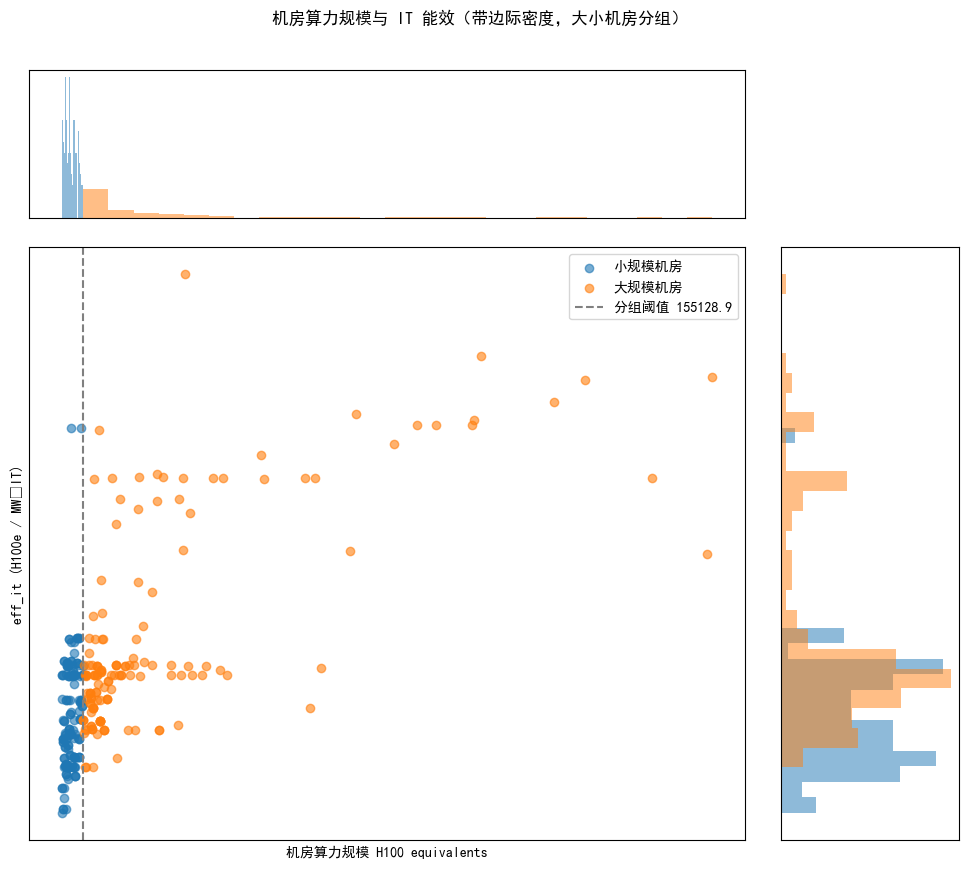

✅图1已保存 scatter_marginal_density.png


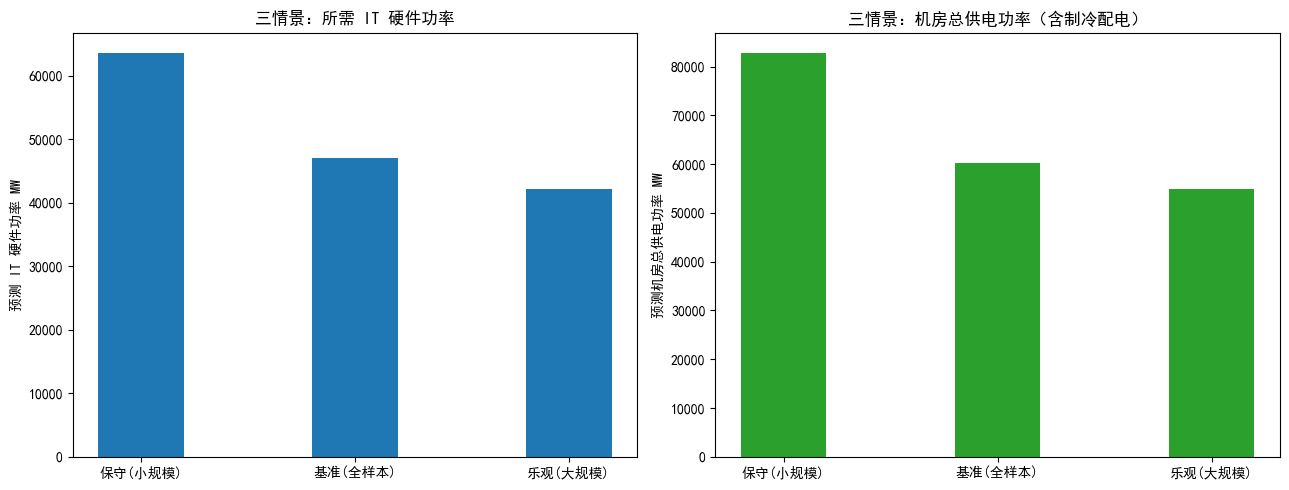

✅图2已保存 three_scenario_bar.png


In [39]:
%matplotlib inline
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

df_actual_full = pd.read_csv("timeline_cleaned_actual.csv", encoding="utf-8-sig")
size_col = "H100 equivalents"
H_add = 48.0 * 10**6   # 情景假设新增算力

# ---------- 1. 按算力中位数划分大小规模组 ----------
size_median = df_actual_full[size_col].median()
df_small = df_actual_full[df_actual_full[size_col] <= size_median].copy()
df_large = df_actual_full[df_actual_full[size_col] > size_median].copy()

print(f"全样本算力中位数(分组阈值): {size_median:.1f} H100 equivalents")
print(f"小规模组样本量: {len(df_small)}；大规模组样本量: {len(df_large)}")

# ---------- 2. 各组计算能效中位数 ----------
med_it_small = df_small["eff_it"].median()
med_total_small = df_small["eff_total"].median()
med_it_all = df_actual_full["eff_it"].median()
med_total_all = df_actual_full["eff_total"].median()
med_it_large = df_large["eff_it"].median()
med_total_large = df_large["eff_total"].median()

# ---------- 3. 三情景电力预测计算 ----------
scenario = pd.DataFrame({
    "情景": ["保守(小规模)", "基准(全样本)", "乐观(大规模)"],
    "eff_it_med": [med_it_small, med_it_all, med_it_large],
    "eff_total_med": [med_total_small, med_total_all, med_total_large]
})
scenario["IT_power_MW"] = H_add / scenario["eff_it_med"]
scenario["Total_power_MW"] = H_add / scenario["eff_total_med"]

print("\n=====三情景预测结果======")
print(scenario.round(2))
scenario.to_csv("three_scenario_prediction.csv", index=False, encoding="utf-8-sig")
print("\n✅三情景结果保存：three_scenario_prediction.csv")

# ---------- 4. 组内相关系数 ----------
corr_small_it = df_small[[size_col, "eff_it"]].corr().iloc[0, 1]
corr_small_total = df_small[[size_col, "eff_total"]].corr().iloc[0, 1]
corr_large_it = df_large[[size_col, "eff_it"]].corr().iloc[0, 1]
corr_large_total = df_large[[size_col, "eff_total"]].corr().iloc[0, 1]

print("\n====组内规模‑能效相关系数====")
print(f"小规模组 r(eff_it):{corr_small_it:.3f}, r(eff_total):{corr_small_total:.3f}")
print(f"大规模组 r(eff_it):{corr_large_it:.3f}, r(eff_total):{corr_large_total:.3f}")

# ---------- 图1：边际密度散点图 ----------
fig = plt.figure(figsize=(12, 10))
gs = fig.add_gridspec(2, 2, width_ratios=[4, 1], height_ratios=[1, 4], wspace=0.08, hspace=0.08)
ax_scatter = fig.add_subplot(gs[1, 0])
ax_xdens = fig.add_subplot(gs[0, 0], sharex=ax_scatter)
ax_ydens = fig.add_subplot(gs[1, 1], sharey=ax_scatter)

ax_scatter.scatter(df_small[size_col], df_small["eff_it"], alpha=0.6, c="#1f77b4", label="小规模机房")
ax_scatter.scatter(df_large[size_col], df_large["eff_it"], alpha=0.6, c="#ff7f0e", label="大规模机房")
ax_scatter.axvline(x=size_median, ls="--", c="gray", label=f"分组阈值 {size_median:.1f}")
ax_scatter.set_xlabel("机房算力规模 H100 equivalents")
ax_scatter.set_ylabel("eff_it (H100e / MW‑IT)")
ax_scatter.legend()

ax_xdens.hist(df_small[size_col], bins=25, alpha=0.5, color="#1f77b4", density=True)
ax_xdens.hist(df_large[size_col], bins=25, alpha=0.5, color="#ff7f0e", density=True)
ax_xdens.set_xticks([])
ax_xdens.set_yticks([])

ax_ydens.hist(df_small["eff_it"], bins=25, alpha=0.5, color="#1f77b4", density=True, orientation="horizontal")
ax_ydens.hist(df_large["eff_it"], bins=25, alpha=0.5, color="#ff7f0e", density=True, orientation="horizontal")
ax_ydens.set_xticks([])
ax_ydens.set_yticks([])

fig.suptitle("机房算力规模与 IT 能效（带边际密度，大小机房分组）", y=0.94)
fig.savefig("scatter_marginal_density.png", dpi=300, bbox_inches="tight")
plt.show()
plt.close(fig)
print("✅图1已保存 scatter_marginal_density.png")

# ---------- 图2：三情景预测柱状对比图 ----------
fig2, (ax_bar1, ax_bar2) = plt.subplots(1, 2, figsize=(13, 5))
x = np.arange(len(scenario))
width = 0.4

ax_bar1.bar(x, scenario["IT_power_MW"], width)
ax_bar1.set_xticks(x)
ax_bar1.set_xticklabels(scenario["情景"])
ax_bar1.set_ylabel("预测 IT 硬件功率 MW")
ax_bar1.set_title("三情景：所需 IT 硬件功率")

ax_bar2.bar(x, scenario["Total_power_MW"], width, color="#2ca02c")
ax_bar2.set_xticks(x)
ax_bar2.set_xticklabels(scenario["情景"])
ax_bar2.set_ylabel("预测机房总供电功率 MW")
ax_bar2.set_title("三情景：机房总供电功率（含制冷配电）")

plt.tight_layout()
fig2.savefig("three_scenario_bar.png", dpi=300, bbox_inches="tight")
plt.show()
plt.close(fig2)
print("✅图2已保存 three_scenario_bar.png")


### 规模分层检验与三情景多情景预测

全样本检验发现机房算力规模与能效存在中等偏强正相关（$r=0.672,\;r=0.656$）。为进一步区分组间差异与组内规模效应，以全样本算力中位数为阈值，将已投运机房划分为小规模、大规模两组。

![算力‑能效带边际密度散点](scatter_marginal_density.png)

组内皮尔逊相关系数：
- 小规模组：$\mathit{eff}_{it}$ 组内相关 = `{corr_small_it:.3f}`；$\mathit{eff}_{total}$ 组内相关 = `{corr_small_total:.3f}`
- 大规模组：$\mathit{eff}_{it}$ 组内相关 = `{corr_large_it:.3f}`；$\mathit{eff}_{total}$ 组内相关 = `{corr_large_total:.3f}`

> 解读提示：若组内相关明显下降，说明全样本观测到的强相关主要来自组间差异，即大、小规模机房本身属于两套不同建设标准，并非单纯机房扩大就自动提升能效。

基于两组与全样本的能效中位数，构建三情景 what‑if 预测：
1. **保守情景**：采用小规模机房能效中位数（能效偏低，对应电力需求更高）
2. **基准情景**：采用全部已投运机房能效中位数
3. **乐观情景**：采用大规模机房能效中位数（能效偏高，对应电力需求更低）

| 情景 | $\mathit{eff}_{it}$ | $\mathit{eff}_{total}$ | 预测 IT 硬件功率(MW) | 预测机房总供电功率(MW) |
| ---- | ------------------- | --------------------- | ------------------ | ---------------------- |
| 保守(小规模) | `{med_it_small:.2f}` | `{med_total_small:.2f}` | `{it_small:.2f}` | `{total_small:.2f}` |
| 基准(全样本) | `{med_it_all:.2f}` | `{med_total_all:.2f}` | `{it_all:.2f}` | `{it_all:.2f}` |
| 乐观(大规模) | `{med_it_large:.2f}` | `{med_total_large:.2f}` | `{it_large:.2f}` | `{total_large:.2f}` |

![三情景预测柱状对比](three_scenario_bar.png)

> 注：全部能效指标仅基于 `is_projection=False` 已投运真实观测样本；48 000 000 等效 H100 为本研究情景假设，不来源于样本。三情景展示预测区间，说明规模分布假设会显著改变电力预测结果。

**更新预测局限性：**
样本存在显著的机房规模‑能效差异；如果未来新建算力项目的规模结构和历史样本不同，预测结果将发生偏移。保守‑基准‑乐观三情景刻画了该不确定性带来的结果区间。


## 十二、后续拓展：芯片端能效的传导问题
本部分为后续可研究方向，本次分析暂不开展实证计算。

理论上新一代GPU芯片硬件能效会持续提升，但芯片纸面的能效增益不一定能够完全传导到真实机房层面的 $\mathit{eff}_{it}$。受机房基础设施、负载调度、混合部署多代硬件等现实条件影响，机房实际能效提升有可能低于芯片标称水平。

本报告第十、十一章的电力预测基于历史混合芯片样本做情景外推，并未显式考虑芯片代际迭代带来的影响。后续可以结合芯片明细数据，进一步探究芯片端能效提升在机房层面的实际传导效果，以此优化电力预测的假设条件。